# ORCA-Pack — PackNet-based

In [1]:
import warnings
warnings.filterwarnings("ignore")

import os, math, time, json, random, gc, socket, urllib.error
from pathlib import Path
from copy import deepcopy
from collections import defaultdict
from contextlib import contextmanager

import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
import torchvision.models as tvm
import torchvision.transforms as T

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
USE_AMP = DEVICE.type == "cuda"
T_START = time.time()
print("Device :", DEVICE)

Device : cuda


In [ ]:
# Configurations

SEED = 67
N_TASKS = 10
CLASSES_PER_TASK = 10
ORDER_ID = 0
IMAGE_SIZE = 32
BATCH_SIZE = 128
NUM_WORKERS = 2
PRETRAINED = True
IMAGENET_WEIGHTS_PATH = None
ALLOW_RANDOM_INIT = False 
GN_GROUPS = 32

EPOCHS_PER_TASK = 30
RETRAIN_EPOCHS = 8
RETRAIN_LR_SCALE = 0.3
CONV_LR = 1e-4
CONV_WD = 0.0
AUX_LR = 1e-3

# Progressive capacity allocation 
USE_PILOT = True
FIXED_PRUNE = 0.5
PRUNE_GRID = (0.3, 0.5, 0.7, 0.8, 0.9, 0.95, 0.98, 0.99, 1.0)
PILOT_EPOCHS = 4
PILOT_TOL = 0.02
PILOT_REF = "tail"
PILOT_SMOOTH = True
PILOT_DIAG_ONE = True

# Fair Share
ALLOC_MODE = "cap"
CAP_X = 3
FS_SLACK = {2: 2.0, 3: 2.0}
FS_DEFAULT_SLACK = 1.0
FLOOR_GAMMA = 1.0
MAX_KEEP_T1 = 0.6

# Smart pruning 
SCORE_A = 0.7
TASK_GN = True
FREE_INIT = "keep"
CFG_KEYS = ("SCORE_A", "ALLOC_MODE", "CAP_X", "FS_SLACK", "FS_DEFAULT_SLACK", "FLOOR_GAMMA", "MAX_KEEP_T1", "USE_PILOT", "FIXED_PRUNE", "TASK_GN", "FREE_INIT", "SEED")

PRESETS = {
    "M1": dict(USE_PILOT=False, FIXED_PRUNE=0.5, ALLOC_MODE="none", SCORE_A=1.0, FREE_INIT="zero", TASK_GN=False),
    "M2": dict(USE_PILOT=False, FIXED_PRUNE=0.5, ALLOC_MODE="none", SCORE_A=1.0, FREE_INIT="zero", TASK_GN=True),
    "A2": dict(USE_PILOT=False, FIXED_PRUNE=0.5),
    "A4": dict(TASK_GN=False),
    "A7": dict(FREE_INIT="zero"),
}

STUDY_PROFILE = "full"
RESUME = True
NOISE_SEED = 68
STUDY_TOL = 0.005
BENCH_A = (0.0, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1.0)
BENCH_P = (0.8, 0.95, 0.99)
BENCH_TASKS = (1, 2)
BENCH_EPOCHS = 5
BENCH_RETRAIN_SEEDS = (0,)
A_FINALISTS_BASE = (1.0, 0.0, 0.7)
X_SWEEP = (2, 5)
FULL_GRID = False
RUN_M1 = True
HEADLINE_RERUN = "auto"
REPLAY_HEADLINE_LOG = True
SAVE_SNAPSHOT = True

# Router Config
FROZEN_ROUTER = {"kind": "lda", "size": 160, "layers": "l3l4", "norm": "none", "tta": True, "shrink": 0.001, "temp": 0.0}
RUN_ROUTER_LAB = False
ROUTER_SIZES = (112, 160, 224)
ROUTER_LAYERS = ("l4", "l3l4")
ROUTER_NORMS = ("none", "l2")
ROUTER_TTA = (False, True)
ROUTER_SHRINK = (0.001, 0.01, 0.05, 0.2, 0.5)
ROUTER_TEMPS = (0.0, 10.0, 50.0)
ROUTER_TOL = 0.003
FUSE_MIN_GAIN = 0.01
ROUTER_HEADLINE = "any"
B_SPACES = ("t1", "own", "in")
AE_DIMS, AE_EPOCHS, AE_LR, AE_BATCH, AE_PATIENCE, AE_NOISE = (256, 64), 80, 1e-3, 256, 15, 0.3
GAUSS_RANK = 128
GREEDY_TOL = 0.001
CLF_EPOCHS, CLF_EPOCHS_SEQ, CLF_LR, CLF_WD, CLF_BATCH, CLF_MEM_PER_CLASS = 40, 40, 1e-3, 1e-4, 256, 20

DATA_DIR = next(Path("/kaggle/input/datasets/prabhanshu22/dl-dataset").rglob("task_order.json")).parent
PLOT_DIR = Path("/kaggle/working/Plots")
PLOT_DIR.mkdir(parents=True, exist_ok=True)
STUDY_JSON = Path("/kaggle/working/orca_nb1_study.json")
SNAP_PATH = Path("/kaggle/working/orca_nb1_winner.pt")

In [3]:
def set_seed(seed=None):
    seed = SEED if seed is None else seed
    random.seed(seed)
    os.environ["PYTHONHASHSEED"] = str(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

_IMAGENET_SD = {}
_WEIGHT_TAGS = {"11ad3fa6": "torchvision IMAGENET1K_V2", "0676ba61": "torchvision IMAGENET1K_V1", "19c8e357": "torchvision IMAGENET1K_V1 (old file)"}

def _is_imagenet_resnet50(sd):
    try:
        return (isinstance(sd, dict) and tuple(sd["conv1.weight"].shape) == (64, 3, 7, 7) and tuple(sd["fc.weight"].shape) == (1000, 2048)
                and "layer4.2.conv3.weight" in sd)
    except Exception:
        return False

def _unwrap_state_dict(obj):
    """Accept a plain state dict or a checkpoint that wraps one; returns a torchvision-style ResNet-50 state dict or None."""
    if isinstance(obj, nn.Module):
        obj = obj.state_dict()
    if isinstance(obj, dict):
        for k in ("state_dict", "model_state_dict", "model"):
            if k in obj and isinstance(obj[k], (dict, nn.Module)):
                return _unwrap_state_dict(obj[k])
        obj = {(k[7:] if k.startswith("module.") else k): v for k, v in obj.items()}
        return obj if _is_imagenet_resnet50(obj) else None
    return None

def _load_candidate(path):
    try:
        try:
            obj = torch.load(path, map_location="cpu", weights_only=True)
        except TypeError:
            obj = torch.load(path, map_location="cpu")
        return _unwrap_state_dict(obj)
    except Exception as e:
        print(f"   skipped {path}: {type(e).__name__}")
        return None

def _explicit_weight_files():
    if not IMAGENET_WEIGHTS_PATH:
        return []
    p = Path(IMAGENET_WEIGHTS_PATH)
    return [p] if p.is_file() else [q for q in sorted(p.rglob("*")) if q.is_file() and q.suffix in (".pth", ".pt", ".bin")]

def _local_weight_files():
    files = []
    try:
        files += sorted((Path(torch.hub.get_dir()) / "checkpoints").glob("resnet50-*.pth"))
    except Exception:
        pass
    root = Path("/kaggle/input")
    if root.exists():
        for q in sorted(root.rglob("*")):
            low = str(q).lower().replace("-", "").replace("_", "")
            if q.is_file() and q.suffix in (".pth", ".pt", ".bin") and "resnet50" in low:
                files.append(q)
    seen, out = set(), []
    for q in files:
        if str(q) not in seen:
            seen.add(str(q))
            out.append(q)
    return sorted(out, key=lambda q: 0 if "11ad3fa6" in q.name else 1)

def get_imagenet_state_dict():
    """State dict of the ImageNet ResNet-50 (cached). Returns None only if ALLOW_RANDOM_INIT = True and nothing was found."""
    if "sd" in _IMAGENET_SD:
        return _IMAGENET_SD["sd"]
    sd, src = None, None
    for q in _explicit_weight_files():
        sd = _load_candidate(q)
        if sd is not None:
            src = f"{q}"
            break
    if sd is None:
        try:
            socket.gethostbyname("download.pytorch.org")
            sd = tvm.ResNet50_Weights.IMAGENET1K_V2.get_state_dict(progress=False)
            src = "downloaded: torchvision IMAGENET1K_V2"
        except (OSError, urllib.error.URLError, RuntimeError) as e:
            print(f"no download possible ({type(e).__name__}: {e}) -> looking for a local copy")
    if sd is None:
        for q in _local_weight_files():
            sd = _load_candidate(q)
            if sd is not None:
                src = f"{q} ({next((v for k, v in _WEIGHT_TAGS.items() if k in q.name), 'unknown torchvision version')})"
                break
    if sd is None:
        msg = ("ImageNet ResNet-50 weights not found and no Internet. Fix (any one of these):\n"
               "  1) Kaggle: right sidebar -> Settings -> Internet = ON (needs a phone-verified account), then run again; or\n"
               "  2) '+ Add Input' a dataset / model that contains a torchvision ResNet-50 .pth (resnet50-11ad3fa6.pth = IMAGENET1K_V2, "
               "resnet50-0676ba61.pth = IMAGENET1K_V1); it is found automatically under /kaggle/input, or set IMAGENET_WEIGHTS_PATH; or\n"
               "  3) debug only: ALLOW_RANDOM_INIT = True (random init: results are NOT comparable and the external router is meaningless).")
        if not ALLOW_RANDOM_INIT:
            raise RuntimeError(msg)
        print("WARNING: " + msg.splitlines()[0] + "\n         ALLOW_RANDOM_INIT = True -> continuing with RANDOM weights.")
        src = "RANDOM INIT"
    _IMAGENET_SD["sd"] = sd
    print(f"ImageNet ResNet-50 weights: {src}")
    return sd

def make_resnet50(pretrained=True):
    """torchvision ResNet-50 (BatchNorm), ImageNet weights from get_imagenet_state_dict(); never touches the network when a local copy exists."""
    net = tvm.resnet50(weights=None)
    sd = get_imagenet_state_dict() if pretrained else None
    if sd is not None:
        net.load_state_dict(sd)
    return net

if PRETRAINED:
    get_imagenet_state_dict()
    
set_seed()
LINEAGE_MODE = ALLOC_MODE
print(f"profile {STUDY_PROFILE!r} | lineage fair-share mode {LINEAGE_MODE!r} | smart pruning a={SCORE_A} | router headline: {ROUTER_HEADLINE}")

Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to /root/.cache/torch/hub/checkpoints/resnet50-11ad3fa6.pth
ImageNet ResNet-50 weights: downloaded: torchvision IMAGENET1K_V2
profile 'full' | lineage fair-share mode 'cap' | smart pruning a=0.7 | router headline: any


In [ ]:
# Data Loading

CIFAR100_MEAN = (0.5071, 0.4865, 0.4409)
CIFAR100_STD  = (0.2673, 0.2564, 0.2762)

eval_tf = [T.ToTensor(), T.Normalize(CIFAR100_MEAN, CIFAR100_STD)]
train_tf = [T.RandomCrop(IMAGE_SIZE, padding=4), T.RandomHorizontalFlip()] + eval_tf
if IMAGE_SIZE != 32:
    train_tf, eval_tf = [T.Resize(IMAGE_SIZE)] + train_tf, [T.Resize(IMAGE_SIZE)] + eval_tf
transform_train, transform_eval = T.Compose(train_tf), T.Compose(eval_tf)

with open(DATA_DIR / "task_order.json") as f:
    meta = json.load(f)
ORDER = meta["task_orders"][ORDER_ID]

class TaskDataset(Dataset):
    def __init__(self, path, transform):
        data = np.load(path)
        self.images, self.labels, self.transform = data["images"], data["labels_local"], transform

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, i):
        return self.transform(Image.fromarray(self.images[i])), int(self.labels[i])

def seed_worker(worker_id):
    s = torch.initial_seed() % 2**32
    np.random.seed(s)
    random.seed(s)

generator = torch.Generator()
generator.manual_seed(SEED)

def get_task_loaders(task_idx):
    """task_idx is the 0-indexed task ID; returns {'train', 'valid', 'test'} loaders."""
    loaders = {}
    for split in ("train", "valid", "test"):
        ds = TaskDataset(DATA_DIR / f"task-{task_idx + 1}" / split / "data.npz", transform_train if split == "train" else transform_eval)
        loaders[split] = DataLoader(ds, batch_size=BATCH_SIZE, shuffle=(split == "train"), num_workers=NUM_WORKERS,
                                    pin_memory=True, worker_init_fn=seed_worker, generator=generator)
    return loaders

def load_tensors(task_idx, split):
    """A whole split as (images, labels) GPU tensors with the deterministic eval transform."""
    ds = TaskDataset(DATA_DIR / f"task-{task_idx + 1}" / split / "data.npz", transform_eval)
    X = torch.stack([ds[i][0] for i in range(len(ds))])
    return X.to(DEVICE), torch.as_tensor(ds.labels, dtype=torch.long).to(DEVICE)

_SPLIT_CACHE = {}

def get_split(t, split):
    """Cached (images, labels) of position t (1-indexed) and split, on the GPU, eval transform."""
    if (t, split) not in _SPLIT_CACHE:
        _SPLIT_CACHE[(t, split)] = load_tensors(ORDER[t - 1], split)
    return _SPLIT_CACHE[(t, split)]

loaders = [get_task_loaders(ORDER[p]) for p in range(N_TASKS)]
print(f"Order {ORDER_ID}: {ORDER}")

Order 0: [3, 8, 1, 4, 9, 0, 2, 6, 7, 5]


In [ ]:
# Extra Helper Functions

FREE = 0

def groups_for(num_channels, preferred=GN_GROUPS):
    if num_channels % preferred == 0:
        return preferred
    return max(math.gcd(preferred, num_channels), 1)

def bn_to_gn(module):
    for name, child in module.named_children():
        if isinstance(child, nn.BatchNorm2d):
            setattr(module, name, nn.GroupNorm(groups_for(child.num_features), child.num_features))
        else:
            bn_to_gn(child)
    return module

def prunable_parameters(model):
    """Backbone conv weights only — GroupNorm affine params, biases and the per-task heads are excluded."""
    gn_modules = {n for n, m in model.named_modules() if isinstance(m, nn.GroupNorm)}
    for name, p in model.named_parameters():
        parent = name.rsplit(".", 1)[0]
        if name.endswith(".weight") and parent not in gn_modules and not name.startswith("head."):
            yield name, p

def norm_parameters(model):
    """GroupNorm affine parameters (weight and bias of every GroupNorm layer)."""
    for mname, m in model.named_modules():
        if isinstance(m, nn.GroupNorm):
            for pname, p in m.named_parameters(recurse=False):
                yield f"{mname}.{pname}", p

# Metrics
def accuracy(logits, y):
    return (logits.argmax(dim=1) == y).float().mean().item()

def empty_accuracy_matrix(n_tasks):
    return np.full((n_tasks, n_tasks), np.nan, dtype=float)

def set_accuracy(R, after_task, eval_task, acc):
    R[after_task, eval_task] = acc

def forgetting(R):
    n = R.shape[0]
    per_task = np.array([R[i, i] - R[n - 1, i] for i in range(n - 1)], dtype=float)
    return {"per_task": per_task.tolist(), "average": float(np.nanmean(per_task)) if per_task.size else 0.0}

def final_average_accuracy(R):
    return float(np.nanmean(R[R.shape[0] - 1]))

def capacity_stats(owner):
    """owner[name]: 0 = free, 1..N_TASKS = owned by that task."""
    total = sum(o.numel() for o in owner.values())
    per_task = {t: sum(int((o == t).sum()) for o in owner.values()) for t in range(1, N_TASKS + 1)}
    free = sum(int((o == FREE).sum()) for o in owner.values())
    return {"total_parameters": total, "per_task_parameters": per_task,
            "allocated_fraction": sum(per_task.values()) / total, "free_fraction": free / total}

def routing_counts(routed, n_tasks):
    """Histogram of the tasks (1..n_tasks) an image set was routed to."""
    return torch.bincount(routed - 1, minlength=n_tasks).cpu().numpy()

def routing_accuracy(conf):
    """Mean over true tasks of the share of its test images routed to the right task (conf: rows = true task)."""
    return float(np.mean(np.diag(conf) / conf.sum(1)))

# Helper Functions
def tail_mean(hist, n=3, key="validation_accuracy"):
    """Mean of the last n epochs of a history entry (an unbiased 'end of training' estimate, unlike the best epoch)."""
    return float(np.mean(hist[key][-n:]))

def pick_with_tolerance(scores, default, tol):
    """Highest-scoring option, but the default wins unless another option beats it by more than tol (validation is noisy).
    `scores` must only ever hold VALIDATION numbers."""
    best = max(scores, key=scores.get)
    return default if scores[default] >= scores[best] - tol else best

def isotonic_nonincreasing(y):
    """Pool-adjacent-violators fit of a monotone non-increasing curve."""
    blocks = []
    for v in np.asarray(y, dtype=float):
        blocks.append([v, 1])
        while len(blocks) > 1 and blocks[-2][0] / blocks[-2][1] < blocks[-1][0] / blocks[-1][1]:
            s, c = blocks.pop()
            blocks[-1][0] += s
            blocks[-1][1] += c
    out = []
    for s, c in blocks:
        out += [s / c] * c
    return np.array(out)

def choose_pilot_ratio(curve, floor, smooth):
    """curve = [(ratio, val acc)] in increasing ratio. Returns (largest ratio whose (smoothed) accuracy >= floor or None, fitted values).
    smooth=True: isotonic fit, then the largest ratio above the floor."""
    ratios = [p for p, _ in curve]
    accs = np.array([a for _, a in curve], dtype=float)
    fitted = isotonic_nonincreasing(accs) if smooth else accs
    ok = fitted >= floor - 1e-12
    chosen = None
    for p, good in zip(ratios, ok):
        if good:
            chosen = p
        elif not smooth:
            break
    return chosen, fitted

# Smart Pruning: S = a * M_hat + (1 - a) * G_hat
def score_weights(grad_mean, weights, owner, a):
    """grad_mean[name]: mean |dL/dw| over one pass of the task's train split. Returns {name: score} for every layer with free weights.
    a = 1.0 is exactly PackNet's per-layer magnitude pruning, a = 0.0 pure gradient pruning (the per-layer normalisation cannot change a
    within-layer ranking at the endpoints)."""
    scores = {}
    for name, w in weights.items():
        free = owner[name] == FREE
        if not bool(free.any()):
            continue
        m = w.data.abs()
        g = grad_mean[name]
        m_hat = m / m[free].mean().clamp_min(1e-12)
        g_hat = g / g[free].mean().clamp_min(1e-12)
        scores[name] = a * m_hat + (1.0 - a) * g_hat
    return scores

def allocation(task_id):
    """Returns dict(p_lo, p_hi, cands, lo_active). The pilot ratio is clipped into [p_lo, p_hi]; the pilot only tries `cands`.
    none : task 1 p_lo = 1 - MAX_KEEP_T1, others p_lo = smallest grid point, p_hi = top of the grid
    cap  : (v2) tasks >= 2: p_lo = 1 - min(beta_t / T_rem, 1)             (a task may keep at most beta_t / T_rem of the free pool)
    capx : like cap with beta = FS_DEFAULT_SLACK, but only for tasks > CAP_X; tasks <= CAP_X behave like none
    floor: (v3) p_hi = min(1 - gamma / T_rem, top) for every task incl. task 1 (a task keeps at least gamma / T_rem of the free pool)"""
    grid = sorted({float(g) for g in PRUNE_GRID})
    top = grid[-1]
    t_rem = N_TASKS - task_id + 1
    p_lo = (1.0 - MAX_KEEP_T1) if task_id == 1 else grid[0]
    p_hi, lo_active = top, task_id == 1
    if (ALLOC_MODE == "cap" and task_id >= 2) or (ALLOC_MODE == "capx" and task_id > CAP_X):
        beta = FS_SLACK.get(task_id, FS_DEFAULT_SLACK) if ALLOC_MODE == "cap" else FS_DEFAULT_SLACK
        p_lo, lo_active = 1.0 - min(beta / t_rem, 1.0), True
    if ALLOC_MODE == "floor":
        p_hi = min(max(1.0 - FLOOR_GAMMA / t_rem, 0.0), top)
    if p_hi < p_lo - 1e-9:
        cands = [float(p_hi)]
    else:
        cs = {g for g in grid if p_lo - 1e-9 <= g <= p_hi + 1e-9}
        if lo_active and p_lo > 1e-9:
            cs.add(float(p_lo))
        if ALLOC_MODE == "floor":
            cs.add(float(p_hi))
        cands = sorted(cs)
    return dict(p_lo=float(p_lo), p_hi=float(p_hi), cands=cands, lo_active=lo_active)

## Model definition
  
* ORCAPackResNet : ResNet-50 (GroupNorm) Backbone + One Head Slot (per-task heads and GroupNorm affines are stored in the manager)
* ORCAPack : Owner map, pruning with Smart-Pruning scores (p = 1.0 keeps nothing, p = 0 keeps the whole free pool), per-task store
* External-Backbone, JointLDA : Frozen ImageNet ResNet-50 features, replay-free joint class-level LDA
* AutoEncoder, fit_gauss, gauss_dist, TaskRouterB : Denoising autoencoder + class-conditional Gaussian per task and feature space

In [6]:
def build_backbone(pretrained=PRETRAINED):
    model = make_resnet50(pretrained)
    model = bn_to_gn(model)
    for m in model.modules():
        if isinstance(m, tvm.resnet.Bottleneck):
            nn.init.zeros_(m.bn3.weight) 
    feature_dim = model.fc.in_features
    model.fc = nn.Identity()
    model.feature_dim = feature_dim
    return model

class ORCAPackResNet(nn.Module):
    """ResNet-50 (GroupNorm) backbone + a classification head. The head is re-initialised for every task; its trained
    state (and the task's GroupNorm affine) is stored per task in `ORCAPack`."""
    def __init__(self, num_classes=CLASSES_PER_TASK):
        super().__init__()
        self.backbone = build_backbone()
        self.head = nn.Linear(self.backbone.feature_dim, num_classes)

    def forward(self, x):
        return self.head(self.backbone(x))

class ORCAPack:
    """PackNet-style owner map with per-task views.
    owner[name] == 0 -> free, trainable by the task being learned
    owner[name] == t -> owned by task t, frozen from then on; task j uses the weights owned by tasks 1..j
    Weights a view does not use are zeroed in the live network (`hide`) and written back afterwards (`unhide`), so
    FREE_INIT = "keep" can leave a task's freed weights untouched and hidden from every earlier view."""
    def __init__(self, model):
        self.model = model
        self.owner = {n: torch.zeros_like(p, dtype=torch.uint8) for n, p in prunable_parameters(model)}
        self.n_total = sum(o.numel() for o in self.owner.values())
        self.heads, self.norms, self.info = {}, {}, {}

    def free_fraction(self):
        return sum(int((o == FREE).sum()) for o in self.owner.values()) / self.n_total

    def mask_gradients(self, owner_id, wd):
        """Train only the weights owned by `owner_id` (0 = free weights, t = task t's kept weights while retraining).
        Weight decay is added here, on those weights only, so frozen weights never decay."""
        for n, p in prunable_parameters(self.model):
            if p.grad is not None:
                if wd:
                    p.grad.add_(p.data, alpha=wd)
                p.grad.masked_fill_(self.owner[n] != owner_id, 0)

    def keep_masks(self, p_ratio, scores):
        """Per layer: the top (1 - p_ratio) share of the FREE weights by score. Exactly k kept, ties cannot over-allocate.
        p_ratio = 1.0 keeps nothing (the task then owns no conv weights); p_ratio = 0 keeps the whole free pool."""
        keep = {}
        for n, _ in prunable_parameters(self.model):
            free = self.owner[n] == FREE
            n_free = int(free.sum())
            k_mask = torch.zeros_like(free)
            if n_free > 0 and p_ratio < 1.0 - 1e-9:
                k = min(max(int(round((1.0 - p_ratio) * n_free)), 1), n_free)
                top = torch.topk(scores[n][free], k).indices
                sel = torch.zeros(n_free, dtype=torch.bool, device=free.device)
                sel[top] = True
                k_mask[free] = sel
            keep[n] = k_mask
        return keep

    def commit(self, keep, task_id):
        for n, k in keep.items():
            self.owner[n][k] = task_id

    def hide(self, upto):
        """Zero every weight task `upto` does not use (free, or owned by a later task); returns what undoes it."""
        stash = {}
        for n, p in prunable_parameters(self.model):
            gone = (self.owner[n] == FREE) | (self.owner[n] > upto)
            stash[n] = (gone, p.data[gone].clone())
            p.data[gone] = 0.0
        return stash

    def unhide(self, stash):
        for n, p in prunable_parameters(self.model):
            gone, vals = stash[n]
            p.data[gone] = vals

    def norm_state(self):
        return {n: p.detach().clone() for n, p in norm_parameters(self.model)}

    def load_norm_state(self, state):
        with torch.no_grad():
            for n, p in norm_parameters(self.model):
                p.copy_(state[n])

    def save_task(self, task_id):
        self.heads[task_id] = deepcopy(self.model.head.state_dict())
        if TASK_GN:
            self.norms[task_id] = self.norm_state()

    @contextmanager
    def view(self, task_id):
        """The network task `task_id` sees: its own owned weights, head and GroupNorm affine. Everything is put back on exit."""
        head_saved = deepcopy(self.model.head.state_dict())
        norm_saved = self.norm_state() if TASK_GN else None
        stash = self.hide(task_id)
        self.model.head.load_state_dict(self.heads[task_id])
        if TASK_GN:
            self.load_norm_state(self.norms[task_id])
        try:
            yield
        finally:
            self.unhide(stash)
            self.model.head.load_state_dict(head_saved)
            if TASK_GN:
                self.load_norm_state(norm_saved)

# Router Parts
def apply_norm(f, norm):
    return F.normalize(f, dim=1) if norm == "l2" else f

def build_features(blocks, layers, norm):
    """blocks = {'l3': (N, 1024), 'l4': (N, 2048)} pooled features -> (N, d) float32, each block normalised separately, then concatenated."""
    names = ("l3", "l4") if layers == "l3l4" else ("l4",)
    return torch.cat([apply_norm(blocks[n].float(), norm) for n in names], 1)

def reduce_classes(logits, temp):
    """(n, t, C) class scores -> (n, t) task scores (higher = more likely): temp * logsumexp(logits / temp) over the task's classes; temp 0 = max."""
    if temp <= 0:
        return logits.max(2).values
    return temp * torch.logsumexp(logits / temp, dim=2)

class ExtBackbone:
    """Frozen ImageNet (BatchNorm) ResNet-50 on up-sampled images: the router's external feature extractor."""
    def __init__(self):
        self.net = make_resnet50(PRETRAINED).to(DEVICE).eval()
        for p in self.net.parameters():
            p.requires_grad_(False)
        vec = lambda v: torch.tensor(v, device=DEVICE).view(1, 3, 1, 1)
        self.c_mean, self.c_std = vec(CIFAR100_MEAN), vec(CIFAR100_STD)
        self.i_mean, self.i_std = vec((0.485, 0.456, 0.406)), vec((0.229, 0.224, 0.225))

    def n_params(self):
        """Parameters needed at inference (everything except the fc layer)."""
        return sum(p.numel() for n, p in self.net.named_parameters() if not n.startswith("fc."))

    def blocks(self, x, size):
        x = x * self.c_std + self.c_mean
        x = (x - self.i_mean) / self.i_std
        x = F.interpolate(x, size=size, mode="bilinear", align_corners=False)
        n = self.net
        x = n.maxpool(n.relu(n.bn1(n.conv1(x))))
        x = n.layer2(n.layer1(x))
        f3 = n.layer3(x)
        f4 = n.layer4(f3)
        return {"l3": f3.mean((2, 3)), "l4": f4.mean((2, 3))}

class JointLDA:
    """Replay-free joint class-level router. Task t contributes its CLASSES_PER_TASK class means and its within-class scatter matrix.
    The pooled covariance of tasks 1..t is rebuilt from the stored scatters, shrunk towards (tr/d) I and inverted once; every seen class
    then gets one LDA logit w_c . x + b_c in the same metric, so no per-task calibration is needed."""
    def __init__(self):
        self.mu, self.scatter, self.n = {}, {}, {}
        self._cov, self._w = {}, {}

    def add_task(self, t, feats, labels):
        f = feats.float()
        mu = torch.stack([f[labels == c].mean(0) for c in range(CLASSES_PER_TASK)])
        zc = f - mu[labels]
        self.mu[t], self.scatter[t], self.n[t] = mu.double(), zc.T @ zc, len(f)

    def cov(self, t):
        if t not in self._cov:
            S = sum(self.scatter[k].double() for k in range(1, t + 1))
            self._cov[t] = S / sum(self.n[k] for k in range(1, t + 1))
        return self._cov[t]

    def means(self, t):
        return torch.cat([self.mu[k] for k in range(1, t + 1)])
        
    def weights(self, t, shrink):
        """LDA weights (d, C*t) and biases (C*t) for the classes of tasks 1..t under the pooled, shrunk covariance."""
        if (t, shrink) not in self._w:
            cov = self.cov(t)
            d = cov.shape[0]
            sig = (1.0 - shrink) * cov + shrink * (torch.trace(cov) / d) * torch.eye(d, device=cov.device, dtype=torch.float64)
            L = torch.linalg.cholesky(sig)
            M = self.means(t)
            W = torch.cholesky_solve(M.T.contiguous(), L)
            self._w[(t, shrink)] = (W, -0.5 * (M.T * W).sum(0))
        return self._w[(t, shrink)]

    @staticmethod
    def logits(X, W, b, t):
        """(n, t, CLASSES_PER_TASK) LDA logits of the rows of X (float64)."""
        return (X.double() @ W + b).view(len(X), t, CLASSES_PER_TASK)

    def ncm(self, X, t):
        """(n, t, CLASSES_PER_TASK) cosine similarity to the class means after centring on the mean of the seen class means."""
        M = self.means(t)
        c = M.mean(0, keepdim=True)
        return (F.normalize(X.double() - c, dim=1) @ F.normalize(M - c, dim=1).T).view(len(X), t, CLASSES_PER_TASK)

class AutoEncoder(nn.Module):
    def __init__(self, in_dim, dims=AE_DIMS):
        super().__init__()
        h, z = dims
        self.net = nn.Sequential(nn.Linear(in_dim, h), nn.ReLU(), nn.Linear(h, z), nn.ReLU(), nn.Linear(z, h), nn.ReLU(), nn.Linear(h, in_dim))

    def forward(self, x):
        return self.net(x)

def fit_gauss(z, y, rank):
    """Class-conditional Gaussian with a shared covariance: class means + one within-class covariance, kept as its top-`rank`
    eigen-subspace plus an isotropic residual variance (probabilistic PCA). z: (N, d) standardised features, y: local labels 0..C-1."""
    n_cls = int(y.max().item()) + 1
    mu = torch.stack([z[y == c].mean(0) for c in range(n_cls)])
    zc = z - mu[y]
    cov = (zc.T @ zc / len(zc)).double().cpu()
    evals, evecs = torch.linalg.eigh(cov)
    d = cov.shape[0]
    rank = int(min(rank, d - 1, len(z) - 1))
    lam = evals[-rank:].clamp_min(1e-6)
    s2 = ((evals.sum() - lam.sum()) / max(d - rank, 1)).clamp_min(1e-6)
    to = lambda t: t.float().to(z.device)
    return dict(mu=mu, U=to(evecs[:, -rank:]), lam=to(lam), s2=float(s2))

@torch.no_grad()
def gauss_dist(g, z, bs=2048):
    """min over classes of the squared Mahalanobis distance of every row of z (lower = more typical for the task)."""
    out = []
    for i in range(0, len(z), bs):
        zb, best = z[i:i + bs], None
        for c in range(g["mu"].shape[0]):
            v = zb - g["mu"][c]
            p = v @ g["U"]
            d2 = (v.pow(2).sum(1) - p.pow(2).sum(1)).clamp_min(0) / g["s2"] + (p.pow(2) / g["lam"]).sum(1)
            best = d2 if best is None else torch.minimum(best, d2)
        out.append(best)
    return torch.cat(out).clamp_min(1e-6)

class TaskRouterB:
    """One routing module per (task, feature space): per-module standardiser (task k's own train statistics, std floored at 10 % of the
    mean std), a denoising autoencoder and a class-conditional Gaussian. Replay-free: module k only ever sees task k's data.
    Raw scores (lower = more typical): ae = reconstruction error, aer = error relative to the sample's energy, gd = Gaussian distance."""

    def __init__(self, spaces):
        self.mods = {s: {} for s in spaces}

    def add(self, space, task_id, mean, std, ae, gauss):
        self.mods[space][task_id] = dict(mean=mean, std=std, ae=ae.eval(), gauss=gauss)

    @torch.no_grad()
    def scores(self, space, task_id, feats, bs=4096):
        m = self.mods[space][task_id]
        z = (feats - m["mean"]) / m["std"]
        err = torch.cat([((m["ae"](z[i:i + bs]) - z[i:i + bs]) ** 2).mean(1) for i in range(0, len(z), bs)])
        return {f"ae_{space}": err,
                f"aer_{space}": err / z.pow(2).mean(1).clamp_min(1e-6),
                f"gd_{space}": gauss_dist(m["gauss"], z)}

## Model summary

In [7]:
model = ORCAPackResNet().to(DEVICE)
orca = ORCAPack(model)
mib = lambda n: n * 4 / 2**20

n_total = sum(p.numel() for p in model.parameters())
n_prunable = sum(p.numel() for _, p in prunable_parameters(model))
n_norm = sum(p.numel() for _, p in norm_parameters(model))
n_head = sum(p.numel() for p in model.head.parameters())

print(f"Total Parameters      : {n_total:,}")
print(f"Prunable Parameters   : {n_prunable:,}  ({n_prunable / n_total:.1%} of total, {len(orca.owner)} conv tensors)")
print(f"Per-Task Extras       : head {n_head:,} | GN affine {n_norm:,} ({'per task' if TASK_GN else 'shared, frozen after task 1'})")
print(f"Allocation            : mode={ALLOC_MODE!r} (cap x={CAP_X}, slack {FS_SLACK}, floor gamma {FLOOR_GAMMA}) | pilot={USE_PILOT} (grid {PRUNE_GRID}, tol {PILOT_TOL}, "
      f"ref {PILOT_REF!r}, smooth {PILOT_SMOOTH}) | max keep t1 {MAX_KEEP_T1} | smart pruning a={SCORE_A} | free init={FREE_INIT!r} | task GN={TASK_GN}")
print(f"Optimiser             : Adam conv lr {CONV_LR:g} (wd {CONV_WD}), GN + head lr {AUX_LR:g} | {EPOCHS_PER_TASK} epochs/task | retrain {RETRAIN_EPOCHS} epochs at scale {RETRAIN_LR_SCALE}")
print(f"Study                 : profile {STUDY_PROFILE!r} | resume {RESUME} | A bench {BENCH_A} on tasks {BENCH_TASKS} at p in {BENCH_P}")
print(f"Router                : frozen external config {FROZEN_ROUTER} | lab {'ON' if RUN_ROUTER_LAB else 'off'} | headline: {ROUTER_HEADLINE}")

Total Parameters      : 23,528,522
Prunable Parameters   : 23,454,912  (99.7% of total, 53 conv tensors)
Per-Task Extras       : head 20,490 | GN affine 53,120 (per task)
Allocation            : mode='cap' (cap x=3, slack {2: 2.0, 3: 2.0}, floor gamma 1.0) | pilot=True (grid (0.3, 0.5, 0.7, 0.8, 0.9, 0.95, 0.98, 0.99, 1.0), tol 0.02, ref 'tail', smooth True) | max keep t1 0.6 | smart pruning a=0.7 | free init='keep' | task GN=True
Optimiser             : Adam conv lr 0.0001 (wd 0.0), GN + head lr 0.001 | 30 epochs/task | retrain 8 epochs at scale 0.3
Study                 : profile 'full' | resume True | A bench (0.0, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1.0) on tasks (1, 2) at p in (0.8, 0.95, 0.99)
Router                : frozen external config {'kind': 'lda', 'size': 160, 'layers': 'l3l4', 'norm': 'none', 'tta': True, 'shrink': 0.001, 'temp': 0.0} | lab off | headline: any


## Training Definiton

In [8]:
criterion = nn.CrossEntropyLoss()

def make_optimizers(scale):
    """[conv-weight optimiser, GN-affine + head optimiser] for the currently trainable parameters (both Adam, no weight decay)."""
    conv = [p for _, p in prunable_parameters(model)]
    conv_ids = {id(p) for p in conv}
    aux = [p for p in model.parameters() if p.requires_grad and id(p) not in conv_ids]
    opts = [torch.optim.Adam(conv, lr=CONV_LR * scale, weight_decay=0)]
    if aux:
        opts.append(torch.optim.Adam(aux, lr=AUX_LR * scale, weight_decay=0))
    return opts

def run_epoch(loader, opts=None, scaler=None, train=True, owner=0, wd=0.0):
    model.train() if train else model.eval()
    total_loss, total_acc, n = 0.0, 0.0, 0
    for x, y in loader:
        x, y = x.to(DEVICE), y.to(DEVICE)
        with torch.set_grad_enabled(train):
            with torch.amp.autocast("cuda", enabled=USE_AMP):
                out = model(x)
                loss = criterion(out, y)
            if train:
                for o in opts:
                    o.zero_grad(set_to_none=True)
                scaler.scale(loss).backward()
                for o in opts:
                    scaler.unscale_(o)
                orca.mask_gradients(owner, wd)
                for o in opts:
                    scaler.step(o)
                scaler.update()
        bs = y.size(0)
        total_loss += loss.item() * bs
        total_acc += accuracy(out, y) * bs
        n += bs
    return total_loss / n, total_acc / n

EPOCH_HDR = (f"{'Epoch':>6} {'T-Loss':>8} {'V-Loss':>8} {'T-Acc':>8} {'V-Acc':>8} {'LR(conv)':>10} {'Time':>7}")

def fit(task_loaders, epochs, scale, owner, select_best, verbose=True):
    """Train the weights owned by `owner` (0 = free weights) + GN affine + head for `epochs`. If select_best, the best-validation epoch
    is kept in memory and reloaded at the end. Returns (history, best)."""
    opts = make_optimizers(scale)
    scheds = [torch.optim.lr_scheduler.CosineAnnealingLR(o, T_max=epochs) for o in opts]
    scaler = torch.amp.GradScaler("cuda", enabled=USE_AMP)
    history = {k: [] for k in ("epoch", "train_loss", "validation_loss", "train_accuracy", "validation_accuracy", "lr", "time")}
    best = {"state": None, "val": -1.0, "epoch": 0}
    if verbose:
        print(EPOCH_HDR)
        print("─" * len(EPOCH_HDR))
    for epoch in range(1, epochs + 1):
        t0 = time.time()
        cur_lr = opts[0].param_groups[0]["lr"]
        tr_loss, tr_acc = run_epoch(task_loaders["train"], opts, scaler, True, owner, CONV_WD)
        va_loss, va_acc = run_epoch(task_loaders["valid"], train=False)
        for s in scheds:
            s.step()
        dt = time.time() - t0
        for k, v in zip(history, [epoch, tr_loss, va_loss, tr_acc, va_acc, cur_lr, dt]):
            history[k].append(v)
        flag = ""
        if select_best and va_acc > best["val"]:
            best = {"state": deepcopy(model.state_dict()), "val": va_acc, "epoch": epoch}
            flag = " ★"
        if verbose:
            print(f"{epoch:>6}  {tr_loss:>8.4f}  {va_loss:>8.4f}  {tr_acc:>8.4f}  {va_acc:>8.4f}  {cur_lr:>10.2e}  {dt:>6.1f}s{flag}")
    if verbose:
        print("─" * len(EPOCH_HDR))
    if select_best:
        model.load_state_dict(best["state"])
        history["best_epoch"], history["best_val"] = best["epoch"], best["val"]
        if verbose:
            print(f"best val acc: {best['val']:.4f} @ epoch {best['epoch']} (reloaded)")
    return history, best

def gradient_pass(loader):
    """Mean over batches of |dL/dw| for every conv weight, at the current weights, one pass over the train split,
    no update, fp32 (autocast off so small gradients do not underflow)."""
    weights = dict(prunable_parameters(model))
    total = {n: torch.zeros_like(p) for n, p in weights.items()}
    model.train()
    n_batches = 0
    for x, y in loader:
        x, y = x.to(DEVICE), y.to(DEVICE)
        model.zero_grad(set_to_none=True)
        criterion(model(x), y).backward()
        for n, p in weights.items():
            if p.grad is not None:
                total[n] += p.grad.abs()
        n_batches += 1
    model.zero_grad(set_to_none=True)
    return {n: t / n_batches for n, t in total.items()}

def pilot_trial(p_ratio, task_id, task_loaders, best_state, scores):
    """Restore the best-epoch weights, prune with `p_ratio` on a temporary owner map, retrain PILOT_EPOCHS and return the validation
    accuracy (mean of the last two epochs) and loss. Nothing leaks into the real owner map."""
    real_owner = orca.owner
    model.load_state_dict(best_state)
    orca.owner = {n: o.clone() for n, o in real_owner.items()}
    orca.commit(orca.keep_masks(p_ratio, scores), task_id)
    orca.hide(task_id)                                   # the free weights are not part of the kept network
    h, _ = fit(task_loaders, PILOT_EPOCHS, RETRAIN_LR_SCALE, owner=task_id, select_best=False, verbose=False)
    orca.owner = real_owner
    return tail_mean(h, 2), tail_mean(h, 2, "validation_loss")

def pilot_search(task_id, task_loaders, best_state, scores, ref_acc, cands, verbose=True):
    """Run every candidate ratio and record the validation accuracy. The curve is smoothed with an isotonic fit (PILOT_SMOOTH) and the
    pilot ratio is the largest candidate whose smoothed accuracy is still >= ref_acc - PILOT_TOL. In floor mode p = 1.0 is only a logged
    diagnostic. Test is never touched. Returns (curve, fitted, p_pilot, all_below_floor, diag_one)."""
    floor = ref_acc - PILOT_TOL
    curve, vlosses = [], []
    for p_ratio in cands:
        acc, vl = pilot_trial(p_ratio, task_id, task_loaders, best_state, scores)
        curve.append((p_ratio, acc))
        vlosses.append(vl)
    diag_one = pilot_trial(1.0, task_id, task_loaders, best_state, scores)[0] if (ALLOC_MODE == "floor" and PILOT_DIAG_ONE) else None
    model.load_state_dict(best_state)
    chosen, fitted = choose_pilot_ratio(curve, floor, PILOT_SMOOTH)
    if verbose:
        for (p_ratio, acc), fit_v, vl in zip(curve, fitted, vlosses):
            print(f"   pilot p={p_ratio:.3f}: val {acc:.4f} (smoothed {fit_v:.4f}, loss {vl:.3f}) | floor {floor:.4f} "
                  f"{'ok' if fit_v >= floor - 1e-12 else 'below floor'}")
        if diag_one is not None:
            print(f"   pilot p=1.000 (diagnostic, never chosen): val {diag_one:.4f}")
    return curve, fitted.tolist(), (chosen if chosen is not None else cands[0]), chosen is None, diag_one

@torch.no_grad()
def predict_correct(X, Y, bs=500):
    """Boolean vector: is each image classified correctly by the network as currently set up (call inside orca.view(j))."""
    model.eval()
    out = []
    for i in range(0, len(X), bs):
        with torch.amp.autocast("cuda", enabled=USE_AMP):
            logits = model(X[i:i + bs])
        out.append(logits.argmax(1) == Y[i:i + bs])
    return torch.cat(out)

@torch.no_grad()
def featurize(fn, X, bs=500):
    out = []
    for i in range(0, len(X), bs):
        with torch.amp.autocast("cuda", enabled=USE_AMP):
            out.append(fn(X[i:i + bs]).float())
    return torch.cat(out)

def freeze_norms():
    for m in model.modules():
        if isinstance(m, nn.GroupNorm):
            for p in m.parameters():
                p.requires_grad_(False)

## Variant engine and study driver


In [9]:
STUDY, SNAPS = {}, {}
STUDY_META = dict(bench={}, tol=STUDY_TOL, noise=None, a_star=None, fs_star=None, headline=None)

def apply_cfg(overrides):
    for k, v in overrides.items():
        assert k in CFG_KEYS, f"unknown config key {k}"
        globals()[k] = v

@contextmanager
def cfg(overrides):
    """Set module-level config values for the duration of a run and restore them afterwards."""
    saved = {k: deepcopy(globals()[k]) for k in CFG_KEYS}
    apply_cfg(overrides)
    try:
        yield
    finally:
        apply_cfg(saved)

def reset_state():
    """Fresh network, owner map and RNG; frees the GPU memory of the previous run."""
    global model, orca
    model = orca = None
    gc.collect()
    torch.cuda.empty_cache()
    set_seed()
    model = ORCAPackResNet().to(DEVICE)
    orca = ORCAPack(model)

def get_rng():
    return (random.getstate(), np.random.get_state(), torch.get_rng_state(), torch.cuda.get_rng_state_all(), generator.get_state())

def set_rng(s):
    random.setstate(s[0]); np.random.set_state(s[1]); torch.set_rng_state(s[2]); torch.cuda.set_rng_state_all(s[3]); generator.set_state(s[4])

# Persistence
def to_jsonable(o):
    if isinstance(o, dict):
        return {str(k): to_jsonable(v) for k, v in o.items()}
    if isinstance(o, (list, tuple)):
        return [to_jsonable(v) for v in o]
    if isinstance(o, np.ndarray):
        return to_jsonable(o.tolist())
    if isinstance(o, (bool, np.bool_)):
        return bool(o)
    if isinstance(o, (int, np.integer)):
        return int(o)
    if isinstance(o, (float, np.floating)):
        return None if math.isnan(float(o)) else float(o)
    return o
    
def save_study():
    with open(STUDY_JSON, "w") as f:
        json.dump(to_jsonable(dict(study=STUDY, meta=STUDY_META)), f)

def load_study():
    if not (RESUME and STUDY_JSON.exists()):
        return
    with open(STUDY_JSON) as f:
        d = json.load(f)
    for name, r in d["study"].items():
        r["R"] = np.array(r["R"], dtype=float)
        r["histories"] = {int(t): h for t, h in r["histories"].items()}
        r["curves"] = {int(t): c for t, c in r["curves"].items()}
        STUDY[name] = r
    STUDY_META.update(d["meta"])
    STUDY_META["bench"] = {int(t): {float(a): {float(p): v for p, v in ps.items()} for a, ps in res.items()} for t, res in STUDY_META.get("bench", {}).items()}
    print(f"resumed {len(STUDY)} stored runs from {STUDY_JSON}: {list(STUDY)}")

def prune_snaps():
    """Keep CPU snapshots only for the baseline and the best-validation candidate (the only two the headline selection can pick)."""
    cand = [n for n in SNAPS if STUDY.get(n, {}).get("candidate")]
    keep = set()
    if cand:
        keep.add(max(cand, key=lambda n: STUDY[n]["V"]))
    if "BASE" in globals() and BASE in SNAPS:
        keep.add(BASE)
    for n in list(SNAPS):
        if n not in keep:
            del SNAPS[n]
    gc.collect()

def run_variant(name, overrides=None, *, verbose=False, keep_snapshot=True, hook=None, candidate=True):
    """One full 10-task run with the config `overrides` applied on top of the defaults. Returns the result record (also in STUDY[name])."""
    overrides = dict(overrides or {})
    with cfg(overrides):
        reset_state()
        t_run = time.time()
        R = empty_accuracy_matrix(N_TASKS)
        hist, hist_r, free_before = {}, {}, {}
        print(f"\n{'=' * 118}\nRUN {name} | {overrides} | mode {ALLOC_MODE} | a {SCORE_A} | seed {SEED}\n{'=' * 118}")
        for task_id in range(1, N_TASKS + 1):
            t_task = time.time()
            set_seed(SEED + task_id)                # per-task seeds: runs with different switches stay comparable
            generator.manual_seed(SEED + task_id)
            task_loaders, task_idx = loaders[task_id - 1], ORDER[task_id - 1]
            if verbose:
                print(f"\n==== Task {task_id}/{N_TASKS}  (task-{task_idx + 1}, classes {meta['class_to_task'][task_idx]}) ====")
            free_before[task_id] = orca.free_fraction()
            model.head.reset_parameters()

            # (1) train the free weights (+ head + GN affine), keep the best-validation epoch
            if verbose:
                print(f"-- (1) training the free weights ({free_before[task_id]:.1%} of the network, {EPOCHS_PER_TASK} epochs) --")
            hist[task_id], best = fit(task_loaders, EPOCHS_PER_TASK, 1.0, 0, True, verbose)
            best_state, ref_best = best["state"], best["val"]
            ref_acc = ref_best if PILOT_REF == "best" else tail_mean(hist[task_id])
            if hook is not None and task_id in BENCH_TASKS:
                rng = get_rng()
                hook(task_id, task_loaders)         # the bench must not change the random stream of the run
                set_rng(rng)

            # (2) Smart-Pruning scores, computed once from the best-epoch weights
            scores = score_weights(gradient_pass(task_loaders["train"]), dict(prunable_parameters(model)), orca.owner, SCORE_A)

            # (3) pilot (validation split) inside [p_lo, p_hi]
            al = allocation(task_id)
            p_lo, p_hi, cands = al["p_lo"], al["p_hi"], al["cands"]
            if verbose:
                kept_lo = (1.0 - p_hi) * free_before[task_id]
                print(f"-- (3) {'pilot over ' + str(cands) if (USE_PILOT and len(cands) > 1) else 'no pilot needed' if len(cands) == 1 else 'fixed prune ratio ' + str(FIXED_PRUNE)} | "
                      f"reference {ref_acc:.4f} ({PILOT_REF}) | allowed prune ratios {p_lo:.3f} .. {p_hi:.3f}"
                      f"{f' | floor: keep at least {kept_lo:.2%} of the network' if ALLOC_MODE == 'floor' else ''} --")
            curve, fitted, all_below, diag_one = [], [], False, None
            if len(cands) == 1:
                p_pilot = cands[0]
            elif USE_PILOT:
                curve, fitted, p_pilot, all_below, diag_one = pilot_search(task_id, task_loaders, best_state, scores, ref_acc, cands, verbose)
            else:
                p_pilot = float(np.clip(FIXED_PRUNE, p_lo, p_hi))
            p_star = float(np.clip(p_pilot, p_lo, p_hi))
            bound = None
            if ALLOC_MODE == "floor":
                bound = "floor" if p_star >= p_hi - 1e-9 else None
            elif al["lo_active"] and USE_PILOT and all_below and p_lo > 1e-9:
                bound = "cap"
            if verbose:
                print(f"   pilot ratio {p_pilot:.3f} | allowed {p_lo:.3f}..{p_hi:.3f} | chosen p* = {p_star:.3f}"
                      f"{'  (cap-bound)' if bound == 'cap' else '  (set by the floor)' if bound == 'floor' else ''}")

            # (4) prune with p*, then retrain the kept weights; the free weights are hidden meanwhile
            model.load_state_dict(best_state)
            orca.commit(orca.keep_masks(p_star, scores), task_id)
            stash = orca.hide(task_id)
            if verbose:
                print(f"-- (4) retraining the kept weights ({RETRAIN_EPOCHS} epochs, free init: {FREE_INIT}) --")
            hist_r[task_id], best_r = fit(task_loaders, RETRAIN_EPOCHS, RETRAIN_LR_SCALE, task_id, True, verbose)
            if FREE_INIT == "keep":
                orca.unhide(stash)                    # freed weights come back with their pre-prune values (hidden from views <= t)
            orca.save_task(task_id)
            if task_id == 1 and not TASK_GN:
                freeze_norms()
            owned = sum(int((o == task_id).sum()) for o in orca.owner.values())
            at_star = next((a for p, a in curve if abs(p - p_star) < 1e-6), None)
            at_one = diag_one if diag_one is not None else next((a for p, a in curve if abs(p - 1.0) < 1e-6), None)
            orca.info[task_id] = dict(p_star=p_star, p_pilot=p_pilot, p_lo=p_lo, p_hi=p_hi, bound=bound, curve=curve, fitted=fitted,
                                      ref=ref_acc, ref_best=ref_best, kept_share=owned / orca.n_total,
                                      kept_of_pool=owned / max(free_before[task_id] * orca.n_total, 1),
                                      pilot_at_star=at_star, pilot_at_one=at_one, final_val=best_r["val"])
            if verbose:
                print(f"   task keeps {owned:,} weights = {owned / orca.n_total:.2%} of the network | free now {orca.free_fraction():.1%} | "
                      f"val before prune {ref_best:.4f} -> after retrain {best_r['val']:.4f}"
                      + (f" (pilot at p*: {at_star:.4f})" if at_star is not None else ""))
            del scores, best_state, stash, best_r

            # (6) oracle test accuracy of every task learned so far (true ID)
            for j in range(1, task_id + 1):
                X_te, Y_te = get_split(j, "test")
                with orca.view(j):
                    set_accuracy(R, task_id - 1, j - 1, predict_correct(X_te, Y_te).float().mean().item())
            if verbose:
                print(f"Task {task_id} done | oracle test acc on tasks 1..{task_id}: {np.round(R[task_id - 1, :task_id], 3).tolist()} | {time.time() - t_task:.0f}s")
            else:
                d = orca.info[task_id]
                print(f"[{name}] task {task_id:>2}/{N_TASKS} | p* {p_star:.3f}{'*' if bound else ' '} | kept {d['kept_share']:>6.2%} | free {orca.free_fraction():>6.1%} | "
                      f"val {ref_best:.3f}->{d['final_val']:.3f} | oracle row mean {np.nanmean(R[task_id - 1, :task_id]):.3f} | {time.time() - t_task:.0f}s")
            torch.cuda.empty_cache()

        info = orca.info
        frozen_gap = float(np.nanmax(np.abs(R[N_TASKS - 1, :N_TASKS - 1] - np.diag(R)[:N_TASKS - 1])))
        cap = capacity_stats(orca.owner)
        res = dict(name=name, overrides=overrides, candidate=candidate, a=float(SCORE_A), mode=ALLOC_MODE, x=int(CAP_X), seed=int(SEED),
                   V=float(np.mean([info[t]["final_val"] for t in range(1, N_TASKS + 1)])), O=final_average_accuracy(R),
                   forgetting=forgetting(R)["average"], frozen_gap=frozen_gap, R=R, unused=cap["free_fraction"],
                   capacity_per_task=[cap["per_task_parameters"][t] / cap["total_parameters"] for t in range(1, N_TASKS + 1)],
                   free_before=[free_before[t] for t in range(1, N_TASKS + 1)],
                   final_val=[info[t]["final_val"] for t in range(1, N_TASKS + 1)], ref=[info[t]["ref"] for t in range(1, N_TASKS + 1)],
                   p_star=[info[t]["p_star"] for t in range(1, N_TASKS + 1)], p_pilot=[info[t]["p_pilot"] for t in range(1, N_TASKS + 1)],
                   p_lo=[info[t]["p_lo"] for t in range(1, N_TASKS + 1)], p_hi=[info[t]["p_hi"] for t in range(1, N_TASKS + 1)],
                   bound=[info[t]["bound"] for t in range(1, N_TASKS + 1)], kept_share=[info[t]["kept_share"] for t in range(1, N_TASKS + 1)],
                   pilot_at_star=[info[t]["pilot_at_star"] for t in range(1, N_TASKS + 1)], pilot_at_one=[info[t]["pilot_at_one"] for t in range(1, N_TASKS + 1)],
                   curves={t: dict(curve=info[t]["curve"], fitted=info[t]["fitted"]) for t in range(1, N_TASKS + 1)},
                   histories={t: dict(train=hist[t], retrain=hist_r[t]) for t in range(1, N_TASKS + 1)},
                   secs=time.time() - t_run, gpu=torch.cuda.get_device_name(0) if USE_AMP else "cpu")
        STUDY[name] = res
        if keep_snapshot:
            SNAPS[name] = dict(overrides=overrides,
                               model={k: v.detach().cpu().clone() for k, v in model.state_dict().items()},
                               owner={n: o.cpu().clone() for n, o in orca.owner.items()},
                               heads=deepcopy(orca.heads), norms={t: {n: v.cpu().clone() for n, v in s.items()} for t, s in orca.norms.items()},
                               info=deepcopy(orca.info))
            prune_snaps()
        save_study()
        n_b = sum(1 for b in res["bound"] if b)
        print(f"[{name}] DONE | V(val) {res['V']:.4f} | O(test) {res['O']:.4f} | forgetting {res['forgetting']:.4f} | frozen gap {frozen_gap:.6f} | "
              f"unused {res['unused']:.1%} | bound tasks {n_b} | {res['secs'] / 60:.1f} min")
        return res

In [10]:
def restore_snapshot(name):
    """Make `model` / `orca` the network of run `name` (config overrides stay applied) — views are then exactly those of the run."""
    snap = SNAPS[name]
    apply_cfg(snap["overrides"])
    reset_state()
    model.load_state_dict(snap["model"])
    for n, o in snap["owner"].items():
        orca.owner[n] = o.to(DEVICE)
    orca.heads = deepcopy(snap["heads"])
    orca.norms = {t: {n: v.to(DEVICE) for n, v in s.items()} for t, s in snap["norms"].items()}
    orca.info = deepcopy(snap["info"])

def print_epoch_table(h):
    print(EPOCH_HDR)
    print("─" * len(EPOCH_HDR))
    best = -1.0
    for i in range(len(h["epoch"])):
        flag = ""
        if h["validation_accuracy"][i] > best:
            best, flag = h["validation_accuracy"][i], " ★"
        print(f"{h['epoch'][i]:>6}  {h['train_loss'][i]:>8.4f}  {h['validation_loss'][i]:>8.4f}  {h['train_accuracy'][i]:>8.4f}  "
              f"{h['validation_accuracy'][i]:>8.4f}  {h['lr'][i]:>10.2e}  {h['time'][i]:>6.1f}s{flag}")
    print("─" * len(EPOCH_HDR))
    print(f"best val acc: {best:.4f} @ epoch {int(np.argmax(h['validation_accuracy'])) + 1} (reloaded)")

def replay_run(name, tasks=None):
    """Re-print the epoch tables, pilot lines and task summaries of a stored run in the original live-log format."""
    r = STUDY[name]
    print(f"\n{'=' * 118}\nREPLAY of run {name} (stored histories) | a {r['a']} | mode {r['mode']}\n{'=' * 118}")
    for t in (tasks or range(1, N_TASKS + 1)):
        task_idx = ORDER[t - 1]
        h = r["histories"][t]
        print(f"\n==== Task {t}/{N_TASKS}  (task-{task_idx + 1}, classes {meta['class_to_task'][task_idx]}) ====")
        print(f"-- (1) training the free weights ({r['free_before'][t - 1]:.1%} of the network, {len(h['train']['epoch'])} epochs) --")
        print_epoch_table(h["train"])
        cur = r["curves"][t]
        floor = (np.mean(h["train"]["validation_accuracy"][-3:]) if PILOT_REF == "tail" else max(h["train"]["validation_accuracy"])) - PILOT_TOL
        print(f"-- (3) allowed prune ratios {r['p_lo'][t - 1]:.3f} .. {r['p_hi'][t - 1]:.3f} --")
        for (p, a), fv in zip(cur["curve"], cur["fitted"]):
            print(f"   pilot p={p:.3f}: val {a:.4f} (smoothed {fv:.4f}) | floor {floor:.4f} {'ok' if fv >= floor - 1e-12 else 'below floor'}")
        print(f"   pilot ratio {r['p_pilot'][t - 1]:.3f} | chosen p* = {r['p_star'][t - 1]:.3f}"
              f"{'  (cap-bound)' if r['bound'][t - 1] == 'cap' else '  (set by the floor)' if r['bound'][t - 1] == 'floor' else ''}")
        print(f"-- (4) retraining the kept weights ({len(h['retrain']['epoch'])} epochs) --")
        print_epoch_table(h["retrain"])
        print(f"   task keeps {r['kept_share'][t - 1]:.2%} of the network | val after retrain {r['final_val'][t - 1]:.4f} | "
              f"oracle test acc (last step) {r['R'][N_TASKS - 1, t - 1]:.4f}")

# Helpers
def vname(a, mode, x=None):
    return f"a{a:.1f}_" + (f"capx{CAP_X if x is None else x}" if mode == "capx" else mode)

def ensure(a, mode, *, x=None, verbose=False, hook=None, candidate=True):
    name = vname(a, mode, x)
    if name in STUDY:
        print(f"[{name}] already stored (V {STUDY[name]['V']:.4f}, O {STUDY[name]['O']:.4f})")
        return name
    ov = dict(SCORE_A=a, ALLOC_MODE=mode)
    if mode == "capx" and x is not None:
        ov["CAP_X"] = x
    run_variant(name, ov, verbose=verbose, hook=hook, candidate=candidate)
    return name

def a_star_or_default():
    v = STUDY_META.get("a_star")
    return 0.7 if v is None else v

def a_label(a):
    return " (magnitude only = PackNet criterion)" if abs(a - 1.0) < 1e-9 else " (gradient only)" if abs(a) < 1e-9 else ""

def study_table(names, title):
    print(f"\n{title}")
    print(f"{'run':<16} {'a':>4} {'mode':<7} {'V (val)':>8} {'O (test)':>9} {'forget':>7} {'unused':>7} {'bound':>6} {'kept% min..max':>15} {'min':>5}")
    for n in names:
        r = STUDY[n]
        ks = [k * 100 for k in r["kept_share"]]
        print(f"{n:<16} {r['a']:>4.1f} {r['mode']:<7} {r['V']:>8.4f} {r['O']:>9.4f} {r['forgetting']:>7.4f} {r['unused']:>7.1%} "
              f"{sum(1 for b in r['bound'] if b):>6} {min(ks):>6.2f}..{max(ks):>5.2f}% {r['secs'] / 60:>5.1f}{a_label(r['a'])}")

def study_matrix():
    rows = sorted({STUDY[n]["a"] for n in STUDY if STUDY[n].get("candidate")}, reverse=True)
    modes = ["none", "cap", "capx", "floor"]
    print(f"\nstudy matrix (V val / O test; '-' = not run; greedy search with interaction check)")
    print(f"{'a':>5} " + " ".join(f"{m:>17}" for m in modes))
    for a in rows:
        cells = []
        for m in modes:
            hit = [r for r in STUDY.values() if r.get("candidate") and abs(r["a"] - a) < 1e-9 and r["mode"] == m and r["seed"] == SEED]
            cells.append(f"{hit[0]['V']:.3f} / {hit[0]['O']:.3f}" if hit else "-")
        print(f"{a:>5.1f} " + " ".join(f"{c:>17}" for c in cells) + a_label(a))

def make_bench_hook(store):
    """Screening bench for the smart-pruning mix: on the best-epoch weights of a task, prune with every `a` at every ratio in BENCH_P,
    retrain BENCH_EPOCHS and record the end-of-retrain validation accuracy. Runs inside the baseline run, no extra training."""
    def hook(task_id, task_loaders):
        t0 = time.time()
        best_state, real_owner = deepcopy(model.state_dict()), orca.owner
        grad = gradient_pass(task_loaders["train"])
        weights = dict(prunable_parameters(model))
        res = {}
        print(f"-- bench of the smart-pruning mix on task {task_id} (validation only, retrain {BENCH_EPOCHS} epochs, p in {BENCH_P}) --")
        for a in BENCH_A:
            scores = score_weights(grad, weights, real_owner, a)
            accs = {}
            for p in BENCH_P:
                vals = []
                for s in BENCH_RETRAIN_SEEDS:
                    set_seed(SEED + task_id + 1000 * (s + 1))
                    generator.manual_seed(SEED + task_id + 1000 * (s + 1))
                    model.load_state_dict(best_state)
                    orca.owner = {n: o.clone() for n, o in real_owner.items()}
                    orca.commit(orca.keep_masks(p, scores), task_id)
                    orca.hide(task_id)
                    h, _ = fit(task_loaders, BENCH_EPOCHS, RETRAIN_LR_SCALE, task_id, False, verbose=False)
                    vals.append(tail_mean(h, 2))
                accs[p] = float(np.mean(vals))
            res[a] = accs
            print(f"   a = {a:>3.1f}{a_label(a):<38}: " + " | ".join(f"p {p}: {v:.4f}" for p, v in accs.items()) + f" | mean {np.mean(list(accs.values())):.4f}")
        orca.owner = real_owner
        model.load_state_dict(best_state)
        store[task_id] = res
        print(f"   bench task {task_id}: {time.time() - t0:.0f}s")
    return hook

load_study()

## Main Training Loop


### 1. Baseline 

In [11]:
BASE = vname(0.7, LINEAGE_MODE)
bench_hook = None
if BASE not in STUDY or not STUDY_META["bench"]:
    bench_hook = make_bench_hook(STUDY_META["bench"])
    STUDY.pop(BASE, None)     # a stored baseline without a bench is re-run once so the bench is available
ensure(0.7, LINEAGE_MODE, verbose=True, hook=bench_hook)
save_study()

b = STUDY[BASE]
print(f"\nreproduction gate G1: baseline oracle O = {b['O']:.4f} (expected 0.765-0.780 for v2 / v1 .777; seeds differ, no exact match) -> "
      f"{'PASS' if 0.765 <= b['O'] <= 0.780 else 'CHECK (outside the expected band)'} | forgetting {b['forgetting']:.4f} | frozen gap {b['frozen_gap']:.6f}")

if STUDY_PROFILE != "lean":
    nname = BASE + f"_seed{NOISE_SEED}"
    if nname not in STUDY:
        run_variant(nname, dict(SCORE_A=0.7, ALLOC_MODE=LINEAGE_MODE, SEED=NOISE_SEED), candidate=False)
    dv = abs(STUDY[BASE]["V"] - STUDY[nname]["V"])
    STUDY_TOL = max(0.005, dv)
    STUDY_META["noise"] = dict(V_seed=STUDY[nname]["V"], V_base=STUDY[BASE]["V"], delta=dv, O_seed=STUDY[nname]["O"], O_base=STUDY[BASE]["O"])
    print(f"\nnoise estimate: V {STUDY[BASE]['V']:.4f} (seed {SEED}) vs {STUDY[nname]['V']:.4f} (seed {NOISE_SEED}) -> |dV| = {dv:.4f}; "
          f"O {STUDY[BASE]['O']:.4f} vs {STUDY[nname]['O']:.4f}")
STUDY_META["tol"] = STUDY_TOL
print(f"STUDY_TOL = {STUDY_TOL:.4f}  (differences below this are reported as ties; the lineage default wins ties)")
save_study()


RUN a0.7_cap | {'SCORE_A': 0.7, 'ALLOC_MODE': 'cap'} | mode cap | a 0.7 | seed 67

==== Task 1/10  (task-4, classes [1, 6, 8, 20, 37, 38, 44, 62, 80, 84]) ====
-- (1) training the free weights (100.0% of the network, 30 epochs) --
 Epoch   T-Loss   V-Loss    T-Acc    V-Acc   LR(conv)    Time
─────────────────────────────────────────────────────────────
     1    2.1076    1.9635    0.2358    0.3020    1.00e-04     5.8s ★
     2    1.7762    1.7457    0.3682    0.3900    9.97e-05     2.1s ★
     3    1.5655    1.5716    0.4422    0.4760    9.89e-05     2.4s ★
     4    1.4299    1.4819    0.4964    0.4660    9.76e-05     2.3s
     5    1.3330    1.2584    0.5222    0.5380    9.57e-05     2.2s ★
     6    1.2444    1.3453    0.5562    0.5400    9.33e-05     2.1s ★
     7    1.1749    1.3711    0.5813    0.5260    9.05e-05     2.1s
     8    1.0957    1.1608    0.6031    0.5880    8.72e-05     2.2s ★
     9    1.0229    1.0333    0.6300    0.6320    8.35e-05     2.3s ★
    10    0.9836  

### 2. Study A 
Smart-pruning mix a (bench screening, then full runs incl. a = 1.0 and a = 0.0)

In [12]:
bench = STUDY_META["bench"]
if bench:
    bench_mean = {a: float(np.mean([np.mean(list(bench[t][a].values())) for t in bench])) for a in BENCH_A if all(a in bench[t] for t in bench)}
    ranked = sorted(bench_mean, key=bench_mean.get, reverse=True)
    print("bench (mean over bench tasks and ratios, validation):")
    for a in BENCH_A:
        if a in bench_mean:
            print(f"   a = {a:>3.1f}{a_label(a):<38}: {bench_mean[a]:.4f}{'  <- best' if a == ranked[0] else ''}")
else:
    bench_mean, ranked = {}, []
    print("no bench stored (resumed session without it): finalists fall back to the base set")

finalists = list(A_FINALISTS_BASE)
if STUDY_PROFILE != "lean" and ranked:
    has = lambda a: any(abs(a - f) < 1e-9 for f in finalists)
    if not has(ranked[0]):
        finalists.append(ranked[0])
    if len(ranked) > 1 and not has(ranked[1]) and bench_mean[ranked[0]] - bench_mean[ranked[1]] <= STUDY_TOL:
        finalists.append(ranked[1])
print(f"\nfull runs for a in {finalists} under the lineage fair-share mode {LINEAGE_MODE!r}")

a_names = {a: ensure(a, LINEAGE_MODE) for a in finalists}
study_table([a_names[a] for a in sorted(finalists, reverse=True)], f"STUDY A — smart-pruning mix a (fair share: {LINEAGE_MODE})")
a_star = pick_with_tolerance({a: STUDY[n]["V"] for a, n in a_names.items()}, 0.7, STUDY_TOL)
STUDY_META["a_star"] = a_star
print(f"\n-> a* = {a_star}{a_label(a_star)}  (default 0.7 wins unless another value beats it by more than {STUDY_TOL:.4f} on V)")
save_study()

bench (mean over bench tasks and ratios, validation):
   a = 0.0 (gradient only)                      : 0.5113  <- best
   a = 0.1                                      : 0.5113
   a = 0.2                                      : 0.5113
   a = 0.3                                      : 0.5113
   a = 0.4                                      : 0.5113
   a = 0.5                                      : 0.5113
   a = 0.6                                      : 0.5113
   a = 0.7                                      : 0.5113
   a = 0.8                                      : 0.5113
   a = 0.9                                      : 0.5113
   a = 1.0 (magnitude only = PackNet criterion) : 0.4665

full runs for a in [1.0, 0.0, 0.7, 0.1] under the lineage fair-share mode 'cap'

RUN a1.0_cap | {'SCORE_A': 1.0, 'ALLOC_MODE': 'cap'} | mode cap | a 1.0 | seed 67
[a1.0_cap] task  1/10 | p* 0.400  | kept 60.00% | free  40.0% | val 0.750->0.742 | oracle row mean 0.729 | 173s
[a1.0_cap] task  2/10 | p* 0.778  

### 3. Study B 
Fair share at `a*`


In [13]:
modes = ["none", "cap", "capx", "floor"] if STUDY_PROFILE != "lean" else ["cap", "capx", "floor"]
fs_names = {m: ensure(a_star, m) for m in modes}
study_table([fs_names[m] for m in modes], f"STUDY B — fair share at a = {a_star} (cap: slack {FS_SLACK}; capx: cap from task {CAP_X + 1}; floor: gamma {FLOOR_GAMMA})")
fs_star = pick_with_tolerance({m: STUDY[n]["V"] for m, n in fs_names.items()}, LINEAGE_MODE, STUDY_TOL)
STUDY_META["fs_star"] = fs_star
print(f"\nnever-binding check: cap-bound tasks per mode: " + ", ".join(f"{m}: {sum(1 for b in STUDY[n]['bound'] if b)}" for m, n in fs_names.items()))
print(f"-> fair share = {fs_star}  (lineage default {LINEAGE_MODE!r} wins unless another mode beats it by more than {STUDY_TOL:.4f} on V)")

for a in sorted({1.0, a_star}):
    ensure(a, fs_star)

if STUDY_PROFILE == "full+":
    for x in X_SWEEP:
        ensure(a_star, "capx", x=x)
    if FULL_GRID:
        for a in sorted({1.0, 0.7, a_star, 0.0}):
            for m in ["none", "cap", "capx", "floor"]:
                ensure(a, m)
if RUN_M1 and "M1" not in STUDY:
    run_variant("M1", PRESETS["M1"], candidate=False)

cand_names = [n for n, r in STUDY.items() if r.get("candidate")]
study_table(sorted(cand_names, key=lambda n: -STUDY[n]["V"]), "ALL candidate runs (sorted by validation V)")
if "M1" in STUDY:
    study_table(["M1"], "reference: M1 = PackNet-R (no pilot, fixed 0.5, a = 1.0, no cap, zero free-init, shared GN, same recipe)")
study_matrix()
save_study()


RUN a0.7_none | {'SCORE_A': 0.7, 'ALLOC_MODE': 'none'} | mode none | a 0.7 | seed 67
[a0.7_none] task  1/10 | p* 0.500  | kept 50.00% | free  50.0% | val 0.750->0.746 | oracle row mean 0.712 | 175s
[a0.7_none] task  2/10 | p* 0.700  | kept 15.00% | free  35.0% | val 0.798->0.782 | oracle row mean 0.735 | 176s
[a0.7_none] task  3/10 | p* 0.800  | kept  7.00% | free  28.0% | val 0.780->0.782 | oracle row mean 0.745 | 178s
[a0.7_none] task  4/10 | p* 0.950  | kept  1.40% | free  26.6% | val 0.830->0.820 | oracle row mean 0.761 | 177s
[a0.7_none] task  5/10 | p* 0.980  | kept  0.53% | free  26.1% | val 0.812->0.794 | oracle row mean 0.765 | 177s
[a0.7_none] task  6/10 | p* 0.800  | kept  5.21% | free  20.9% | val 0.802->0.794 | oracle row mean 0.764 | 176s
[a0.7_none] task  7/10 | p* 0.800  | kept  4.17% | free  16.7% | val 0.780->0.772 | oracle row mean 0.765 | 174s
[a0.7_none] task  8/10 | p* 1.000  | kept  0.00% | free  16.7% | val 0.826->0.808 | oracle row mean 0.774 | 174s
[a0.7_none

In [14]:
HEAD = pick_with_tolerance({n: STUDY[n]["V"] for n in cand_names}, BASE, STUDY_TOL)
STUDY_META["headline"] = HEAD
print(f"-> HEADLINE run = {HEAD}  (V {STUDY[HEAD]['V']:.4f} val, O {STUDY[HEAD]['O']:.4f} test; baseline {BASE}: V {STUDY[BASE]['V']:.4f}); "
      f"ties within {STUDY_TOL:.4f} go to the baseline")

if HEAD in SNAPS and HEADLINE_RERUN != "always":
    restore_snapshot(HEAD)
    print("snapshot restored (no re-training)")
else:
    prev = STUDY[HEAD]["V"]
    print("re-running the headline configuration" + (" (snapshot missing)" if HEAD not in SNAPS else " (HEADLINE_RERUN='always')"))
    ov = STUDY[HEAD]["overrides"]
    STUDY.pop(HEAD)
    run_variant(HEAD, ov, verbose=True, candidate=True)
    print(f"reproduction check: V stored {prev:.4f} vs re-run {STUDY[HEAD]['V']:.4f} (|d| = {abs(prev - STUDY[HEAD]['V']):.4f})")
    restore_snapshot(HEAD)
if SAVE_SNAPSHOT:
    torch.save(dict(name=HEAD, **SNAPS[HEAD]), SNAP_PATH)
    print(f"winner snapshot saved to {SNAP_PATH}")
HR = STUDY[HEAD]
R = HR["R"]
if REPLAY_HEADLINE_LOG and HEAD in STUDY:
    replay_run(HEAD)

-> HEADLINE run = a0.7_cap  (V 0.7862 val, O 0.7740 test; baseline a0.7_cap: V 0.7862); ties within 0.0050 go to the baseline
snapshot restored (no re-training)
winner snapshot saved to /kaggle/working/orca_nb1_winner.pt

REPLAY of run a0.7_cap (stored histories) | a 0.7 | mode cap

==== Task 1/10  (task-4, classes [1, 6, 8, 20, 37, 38, 44, 62, 80, 84]) ====
-- (1) training the free weights (100.0% of the network, 30 epochs) --
 Epoch   T-Loss   V-Loss    T-Acc    V-Acc   LR(conv)    Time
─────────────────────────────────────────────────────────────
     1    2.1076    1.9635    0.2358    0.3020    1.00e-04     5.8s ★
     2    1.7762    1.7457    0.3682    0.3900    9.97e-05     2.1s ★
     3    1.5655    1.5716    0.4422    0.4760    9.89e-05     2.4s ★
     4    1.4299    1.4819    0.4964    0.4660    9.76e-05     2.3s
     5    1.3330    1.2584    0.5222    0.5380    9.57e-05     2.2s ★
     6    1.2444    1.3453    0.5562    0.5400    9.33e-05     2.1s ★
     7    1.1749    1.3711

## Evaluation summary

In [15]:
final_oracle, forget_oracle = final_average_accuracy(R), forgetting(R)
frozen_gap = float(np.nanmax(np.abs(R[N_TASKS - 1, :N_TASKS - 1] - np.diag(R)[:N_TASKS - 1])))
cap = capacity_stats(orca.owner)
per_task_alloc = [cap["per_task_parameters"][t] / cap["total_parameters"] for t in range(1, N_TASKS + 1)]
V2_ORACLE = [.724, .757, .768, .790, .807, .751, .750, .803, .756, .785]      # v2, order 0 (position 1..10)
V1_ORACLE = [.705, .776, .772, .812, .792, .759, .761, .812, .794, .783]
V3_ORACLE = [.724, .819, .833, .850, .834, .804, .828, .868, .848, .840]

print(f"Headline run                                     : {HEAD}  (a = {HR['a']}{a_label(HR['a'])}, fair share {HR['mode']})")
print(f"Final average accuracy, ORACLE (true task ID)   : {final_oracle:.4f}   (PackNet .637 | EvE .710 | PiggyBack .773 | ORCA v1 .777 | v2 .769 | v3 .825 on order 0)")
print(f"Mean validation accuracy V (selection metric)    : {HR['V']:.4f}")
print(f"Average forgetting, oracle                       : {forget_oracle['average']:.4f}")
print(f"Max |R[T-1,i] - R[i,i]| over earlier tasks        : {frozen_gap:.6f}   (0 = frozen owners really frozen)")
print(f"Capacity allocated : {cap['allocated_fraction']:.1%} | free (unused) : {cap['free_fraction']:.1%}")
print(f"Kept share per task: {[round(x * 100, 2) for x in per_task_alloc]} %")
print(f"Oracle per position (this run): {np.round(np.diag(R), 3).tolist()}")
print(f"Run time of the headline run: {HR['secs'] / 60:.1f} min | total notebook time so far: {(time.time() - T_START) / 60:.1f} min")

Headline run                                     : a0.7_cap  (a = 0.7, fair share cap)
Final average accuracy, ORACLE (true task ID)   : 0.7740   (PackNet .637 | EvE .710 | PiggyBack .773 | ORCA v1 .777 | v2 .769 | v3 .825 on order 0)
Mean validation accuracy V (selection metric)    : 0.7862
Average forgetting, oracle                       : 0.0000
Max |R[T-1,i] - R[i,i]| over earlier tasks        : 0.000000   (0 = frozen owners really frozen)
Capacity allocated : 81.7% | free (unused) : 18.3%
Kept share per task: [50.0, 10.0, 10.0, 1.5, 1.43, 5.41, 2.17, 0.0, 0.97, 0.19] %
Oracle per position (this run): [0.712, 0.763, 0.783, 0.801, 0.776, 0.758, 0.768, 0.826, 0.765, 0.788]
Run time of the headline run: 38.5 min | total notebook time so far: 240.7 min


## Router study 

A task's view never changes after it is learned, so every router is built after the last task from each task's own train / valid images only.

Common interface: score_fn(t) -> (n_eval, t) scores (lower = more typical) on the validation + test images of all tasks.
* **Family A** — basic task-ID classifier on frozen features (spaces t1 = task-1 view, ext = frozen ImageNet): linear / mlp, regimes seq (replay-free, fine-tuned task by task),
  mem20 (20 stored feature vectors per class; not replay-free), joint (all train features: non-continual upper bound for a learned classifier).
* **Family B** — v2 router: per task and space a denoising autoencoder + class-conditional Gaussian (+ head confidence), z-calibrated, mean-of-z fusions.
* **Family C** — v3 router: joint LDA on frozen ImageNet features (external), joint LDA on the task-1 view and head energy (internal), fusions with head energy.

In [16]:
SPLIT_CODE = {"valid": 0, "test": 1}

def make_eval():
    """Validation + test images of all tasks: images, true position, split code (0 valid, 1 test)."""
    xs, ts, ss = [], [], []
    for t in range(1, N_TASKS + 1):
        for s in ("valid", "test"):
            X, _ = get_split(t, s)
            xs.append(X)
            ts.append(torch.full((len(X),), t, dtype=torch.long, device=DEVICE))
            ss.append(torch.full((len(X),), SPLIT_CODE[s], dtype=torch.long, device=DEVICE))
    return dict(X=torch.cat(xs), task=torch.cat(ts), split=torch.cat(ss))

def _rows(ev, n_seen, split):
    return (ev["task"] <= n_seen) & (ev["split"] == SPLIT_CODE[split])

def route_acc(S, ev, n_seen, split):
    """Share of the images of tasks 1..n_seen routed to their own task (argmin over the first n_seen columns)."""
    m = _rows(ev, n_seen, split)
    return ((S[m][:, :n_seen].argmin(1) + 1) == ev["task"][m]).float().mean().item()

def top2_acc(S, ev, n_seen, split):
    m = _rows(ev, n_seen, split)
    idx = torch.topk(-S[m][:, :n_seen], min(2, n_seen), dim=1).indices + 1
    return (idx == ev["task"][m][:, None]).any(1).float().mean().item()

def routed_results(score_fn, ev):
    """R_routed (after step t, tasks 1..t, routing among the t seen tasks), routing accuracy and confusion matrix per step."""
    R_r = empty_accuracy_matrix(N_TASKS)
    acc_by_step, conf_by_step = {}, {}
    for t in range(1, N_TASKS + 1):
        S = score_fn(t)[:, :t]
        cm = np.zeros((t, t))
        for j in range(1, t + 1):
            rows = (ev["task"] == j) & (ev["split"] == SPLIT_CODE["test"])
            pred = S[rows].argmin(1) + 1
            cm[j - 1] = routing_counts(pred, t)
            R_r[t - 1, j - 1] = (CORRECT[j] & (pred == j)).float().mean().item()
        conf_by_step[t], acc_by_step[t] = cm, routing_accuracy(cm)
    return R_r, acc_by_step, conf_by_step

def zcal(raw, ev, ks, tf=lambda x: x):
    """z-score of the score, using each task's own validation images as the in-task reference -> comparable across tasks."""
    valid = ev["split"] == SPLIT_CODE["valid"]
    t = tf(raw)
    cols = []
    for i, k in enumerate(ks):
        v = t[valid & (ev["task"] == k), i]
        cols.append((t[:, i] - v.mean()) / v.std().clamp_min(1e-6))
    return torch.stack(cols, 1)

_EXT = {}
def get_ext():
    if "net" not in _EXT:
        _EXT["net"] = ExtBackbone()
    return _EXT["net"]

@torch.no_grad()
def ext_blocks(X, size, flip, bs=500):
    l3, l4 = [], []
    for i in range(0, len(X), bs):
        xb = torch.flip(X[i:i + bs], dims=[3]) if flip else X[i:i + bs]
        with torch.amp.autocast("cuda", enabled=USE_AMP):
            b = get_ext().blocks(xb, size)
        l3.append(b["l3"].float()); l4.append(b["l4"].float())
    return {"l3": torch.cat(l3), "l4": torch.cat(l4)}

def ext_feats(X, size, layers, norm, tta):
    f = build_features(ext_blocks(X, size, False), layers, norm)
    if tta:
        f = (f + build_features(ext_blocks(X, size, True), layers, norm)) / 2
    return f
    
@torch.no_grad()
def view_feats(k, X, bs=500):
    """Pooled 2048-d features and head logits of task k's own view for every image of X."""
    fs, ls = [], []
    with orca.view(k):
        model.eval()
        for i in range(0, len(X), bs):
            with torch.amp.autocast("cuda", enabled=USE_AMP):
                f = model.backbone(X[i:i + bs])
                l = model.head(f)
            fs.append(f.float()); ls.append(l.float())
    return torch.cat(fs), torch.cat(ls)

def space_feats(space, X, k=None):
    """Training-time features of images X (no TTA) in a router feature space."""
    if space == "t1":
        with orca.view(1):
            model.eval()
            return featurize(model.backbone, X)
    if space == "own":
        return view_feats(k, X)[0]
    if space == "in":
        return ext_feats(X, 112, "l4", "none", False)
    if space == "ext":
        return ext_feats(X, FROZEN_ROUTER["size"], FROZEN_ROUTER["layers"], FROZEN_ROUTER["norm"], False)
    raise ValueError(space)

def flip_aug(t, split="train"):
    X, y = get_split(t, split)
    return torch.cat([X, torch.flip(X, dims=[3])]), torch.cat([y, y])

t_router = time.time()
EV = make_eval()
CORRECT, EV_LOG = {}, {}
for j in range(1, N_TASKS + 1):
    X_te, Y_te = get_split(j, "test")
    with orca.view(j):
        CORRECT[j] = predict_correct(X_te, Y_te)
    EV_LOG[j] = view_feats(j, EV["X"])[1]
ks_all = list(range(1, N_TASKS + 1))
ENG = torch.stack([-torch.logsumexp(EV_LOG[k], 1) for k in ks_all], 1)
print(f"oracle check on the restored network: {np.mean([CORRECT[j].float().mean().item() for j in ks_all]):.4f} (stored O {HR['O']:.4f})")

# evaluation-time features 
EVF = {"t1": space_feats("t1", EV["X"]),
       "ext": ext_feats(EV["X"], FROZEN_ROUTER["size"], FROZEN_ROUTER["layers"], FROZEN_ROUTER["norm"], FROZEN_ROUTER["tta"]),
       "in": space_feats("in", EV["X"])}
TRF = {s: {} for s in ("t1", "ext")}
YTR = {}
for t in ks_all:
    Xa, ya = flip_aug(t)
    YTR[t] = ya
    for s in TRF:
        TRF[s][t] = space_feats(s, Xa)

oracle check on the restored network: 0.7740 (stored O 0.7740)


In [ ]:
# Family C

CANDS = {}

def lda_scores(lda, Q, t, c):
    """(n, t) scores, lower = more typical, of the joint LDA / NCM router among the first t tasks."""
    if c["kind"] == "ncm":
        sc = reduce_classes(lda.ncm(Q, t), 0.0)
    else:
        W, b = lda.weights(t, c["shrink"])
        sc = reduce_classes(JointLDA.logits(Q, W, b, t), c["temp"])
    return (-sc).float()

def acc_of(sc, true):
    return ((sc.argmax(1) + 1) == true).float().mean().item()

def top2_of(sc, true):
    return ((torch.topk(sc, 2, dim=1).indices + 1) == true[:, None]).any(1).float().mean().item()

def router_lab():
    """External joint LDA / NCM router over a grid of feature spaces (network independent; validation selects, test is only reported)."""
    Xv = torch.cat([get_split(t, "valid")[0] for t in ks_all]); tv = torch.cat([torch.full((len(get_split(t, "valid")[0]),), t, device=DEVICE) for t in ks_all])
    Xt = torch.cat([get_split(t, "test")[0] for t in ks_all]); tt = torch.cat([torch.full((len(get_split(t, "test")[0]),), t, device=DEVICE) for t in ks_all])
    true = {"valid": tv, "test": tt}
    rows = []
    for size in ROUTER_SIZES:
        t0 = time.time()
        train = {t: (ext_blocks(get_split(t, "train")[0], size, False), ext_blocks(get_split(t, "train")[0], size, True)) for t in ks_all}
        evb = {n: (ext_blocks(X, size, False), ext_blocks(X, size, True)) for n, X in (("valid", Xv), ("test", Xt))}
        for layers in ROUTER_LAYERS:
            for norm in ROUTER_NORMS:
                lda = JointLDA()
                for t in ks_all:
                    y = get_split(t, "train")[1]
                    f = torch.cat([build_features(train[t][0], layers, norm), build_features(train[t][1], layers, norm)])
                    lda.add_task(t, f, torch.cat([y, y]))
                for tta in ROUTER_TTA:
                    Q = {}
                    for n in ("valid", "test"):
                        q = build_features(evb[n][0], layers, norm)
                        if tta:
                            q = (q + build_features(evb[n][1], layers, norm)) / 2
                        Q[n] = q.double()
                    base = dict(size=size, layers=layers, norm=norm, tta=tta)
                    sc = {n: reduce_classes(lda.ncm(Q[n], N_TASKS), 0.0) for n in Q}
                    rows.append(dict(base, kind="ncm", shrink=None, temp=0.0, val=acc_of(sc["valid"], true["valid"]),
                                     test=acc_of(sc["test"], true["test"]), top2=top2_of(sc["test"], true["test"])))
                    for shrink in ROUTER_SHRINK:
                        W, b = lda.weights(N_TASKS, shrink)
                        lg = {n: JointLDA.logits(Q[n], W, b, N_TASKS) for n in Q}
                        for temp in ROUTER_TEMPS:
                            sc = {n: reduce_classes(lg[n], temp) for n in Q}
                            rows.append(dict(base, kind="lda", shrink=shrink, temp=temp, val=acc_of(sc["valid"], true["valid"]),
                                             test=acc_of(sc["test"], true["test"]), top2=top2_of(sc["test"], true["test"])))
                    del Q
                del lda
        del train, evb
        torch.cuda.empty_cache()
        print(f"   input size {size}px: {len(rows)} candidates so far | {time.time() - t0:.0f}s")
    return rows

def select_router(rows):
    """Best validation accuracy; among the candidates within ROUTER_TOL of it the cheapest at inference wins."""
    best = max(r["val"] for r in rows)
    near = [r for r in rows if r["val"] >= best - ROUTER_TOL]
    pick = min(near, key=lambda r: (r["size"], len(r["layers"]), r["tta"], -r["val"]))
    return {k: pick[k] for k in ("kind", "size", "layers", "norm", "tta", "shrink", "temp")}

ROUTER_CFG = dict(FROZEN_ROUTER)
if RUN_ROUTER_LAB:
    LAB_ROWS = router_lab()
    ROUTER_CFG = select_router(LAB_ROWS)
    print("best 8 lab candidates by validation:")
    for r in sorted(LAB_ROWS, key=lambda r: -r["val"])[:8]:
        print(f"   {r['size']}px {r['layers']} norm {r['norm']} tta {int(r['tta'])} {r['kind']} shrink {r['shrink']} T {r['temp']} | val {r['val']:.3f} test {r['test']:.3f} top-2 {r['top2']:.3f}")
    print("FROZEN_ROUTER =", ROUTER_CFG)
    if ROUTER_CFG != FROZEN_ROUTER:
        print("note: the lab picked a different config than FROZEN_ROUTER; the features cached above use FROZEN_ROUTER, re-run the cell with FROZEN_ROUTER updated to use the new one")

ext_lda = JointLDA()
for t in ks_all:
    ext_lda.add_task(t, TRF["ext"][t], YTR[t])
Q_EXT = EVF["ext"].double()
ext_fn = lambda t, _c=ROUTER_CFG: lda_scores(ext_lda, Q_EXT, t, _c)

int_lda, Q_INT = {}, {}
for nm in ROUTER_NORMS:
    int_lda[nm] = JointLDA()
    for t in ks_all:
        int_lda[nm].add_task(t, apply_norm(TRF["t1"][t], nm), YTR[t])
    Q_INT[nm] = apply_norm(EVF["t1"], nm).double()
int_rows = []
for nm in ROUTER_NORMS:
    for o in [dict(kind="ncm", shrink=None, temp=0.0)] + [dict(kind="lda", shrink=s, temp=tp) for s in ROUTER_SHRINK for tp in ROUTER_TEMPS]:
        c = dict(o, norm=nm)
        int_rows.append(dict(c, val=route_acc(lda_scores(int_lda[nm], Q_INT[nm], N_TASKS, c), EV, N_TASKS, "valid")))
INT_CFG = max(int_rows, key=lambda r: r["val"])
int_fn = lambda t: lda_scores(int_lda[INT_CFG["norm"]], Q_INT[INT_CFG["norm"]], t, INT_CFG)
eng_fn = lambda t: zcal(ENG[:, :t], EV, list(range(1, t + 1)))

def cached(fn):
    memo = {}
    def g(t):
        if t not in memo:
            memo[t] = fn(t)
        return memo[t]
    return g

def fuse_fn(fn_a, raw_b):
    """Mean of the z-calibrated scores of a router and of a raw head-score matrix."""
    return lambda t: (zcal(fn_a(t), EV, list(range(1, t + 1))) + zcal(raw_b(t), EV, list(range(1, t + 1)))) / 2

ext_fn, int_fn, eng_fn = cached(ext_fn), cached(int_fn), cached(eng_fn)
d_ext = Q_EXT.shape[1]
ext_extra = (N_TASKS * CLASSES_PER_TASK * d_ext + d_ext ** 2) * 2 / 2**20            # fp16 class means + one shared covariance
int_extra = (N_TASKS * CLASSES_PER_TASK * 2048 + 2048 ** 2) * 2 / 2**20
ext_backbone_mib = get_ext().n_params() * 2 / 2**20
eng_raw = lambda t: ENG[:, :t]
CANDS["C: ext_lda"] = dict(family="C", space="ext", external=True, replay_free=True, score=ext_fn, extra=ext_extra + ext_backbone_mib, passes="1 external pass (x2 TTA) + 1")
CANDS["C: ext_lda+eng_own"] = dict(family="C", space="ext+own", external=True, replay_free=True, score=cached(fuse_fn(ext_fn, eng_raw)), extra=ext_extra + ext_backbone_mib,
                                   passes="1 external + every seen view", base="C: ext_lda")
CANDS["C: int_eng_own"] = dict(family="C", space="own", external=False, replay_free=True, score=eng_fn, extra=0.0, passes="every seen view (T passes)")
CANDS["C: int_lda_t1"] = dict(family="C", space="t1", external=False, replay_free=True, score=int_fn, extra=int_extra, passes="1 (task-1 view) + 1")
CANDS["C: int_lda_t1+eng_own"] = dict(family="C", space="t1+own", external=False, replay_free=True, score=cached(fuse_fn(int_fn, eng_raw)), extra=int_extra,
                                      passes="every seen view (T passes)")
print(f"family C ready | internal LDA config {INT_CFG} | external config {ROUTER_CFG}")

family C ready | internal LDA config {'kind': 'lda', 'shrink': 0.001, 'temp': 0.0, 'norm': 'none', 'val': 0.38099998235702515} | external config {'kind': 'lda', 'size': 160, 'layers': 'l3l4', 'norm': 'none', 'tta': True, 'shrink': 0.001, 'temp': 0.0}


In [ ]:
# Family A : basic task-ID classifier 

def make_clf(arch, d):
    if arch == "linear":
        return nn.Linear(d, N_TASKS).to(DEVICE)
    return nn.Sequential(nn.Linear(d, 512), nn.ReLU(), nn.Dropout(0.2), nn.Linear(512, N_TASKS)).to(DEVICE)

def train_clf(clf, X, y, t, epochs, seed):
    """Task-balanced cross-entropy over the first t task slots."""
    g = torch.Generator(device=X.device)
    g.manual_seed(seed)
    opt = torch.optim.Adam(clf.parameters(), lr=CLF_LR, weight_decay=CLF_WD)
    w = 1.0 / torch.bincount(y, minlength=N_TASKS).float().clamp_min(1)
    for _ in range(epochs):
        clf.train()
        perm = torch.randperm(len(X), device=X.device, generator=g)
        for i in range(0, len(X), CLF_BATCH):
            idx = perm[i:i + CLF_BATCH]
            wi = w[y[idx]]
            loss = (F.cross_entropy(clf(X[idx])[:, :t], y[idx], reduction="none") * wi).sum() / wi.sum()
            opt.zero_grad()
            loss.backward()
            opt.step()
    return clf

class ClfRouter:
    """Task-ID classifier on frozen features. regime: 'seq' (one classifier, fine-tuned on each new task only: replay-free),
    'mem20' (20 stored feature vectors per class, retrained from scratch every step: NOT replay-free), 'joint' (all train features of
    tasks 1..t: non-continual upper bound). Features are standardised with the task-1 train statistics (fixed forever)."""

    def __init__(self, space, arch, regime):
        self.space, self.arch, self.regime = space, arch, regime
        f1 = TRF[space][1].float()
        self.mean = f1.mean(0, keepdim=True)
        std = f1.std(0, keepdim=True)
        self.std = std.clamp_min(0.1 * float(std.mean()) + 1e-6)
        self.Q = (EVF[space].float() - self.mean) / self.std
        self.d = self.Q.shape[1]
        self.memo, self.persist, self.done = {}, None, 0
        self.mem = {}
        gen = torch.Generator(device="cpu")
        gen.manual_seed(SEED + 7)
        for t in ks_all:                                         # fixed random exemplars: first half of the stored rows = un-flipped images
            n = len(YTR[t]) // 2
            yl = YTR[t][:n].cpu()
            idx = torch.cat([torch.nonzero(yl == c)[:, 0][torch.randperm(int((yl == c).sum()), generator=gen)[:CLF_MEM_PER_CLASS]] for c in range(CLASSES_PER_TASK)])
            self.mem[t] = ((TRF[space][t][idx.to(DEVICE)].float() - self.mean) / self.std)

    def feats(self, t):
        return (TRF[self.space][t].float() - self.mean) / self.std

    def scores(self, t):
        if t in self.memo:
            return self.memo[t]
        seed = SEED + 100 + t
        if self.regime == "seq":
            if self.persist is None:
                torch.manual_seed(SEED + 100)
                self.persist = make_clf(self.arch, self.d)
            while self.done < t:
                self.done += 1
                X = self.feats(self.done)
                y = torch.full((len(X),), self.done - 1, dtype=torch.long, device=DEVICE)
                train_clf(self.persist, X, y, self.done, CLF_EPOCHS_SEQ, SEED + 100 + self.done)
                self.persist.eval()
                with torch.no_grad():                                      # the classifier as it was after step `done` (no leakage from later steps)
                    self.memo[self.done] = -F.log_softmax(self.persist(self.Q)[:, :self.done], dim=1)
            return self.memo[t]
        else:
            if self.regime == "joint":
                Xs = [self.feats(k) for k in range(1, t + 1)]
                ys = [torch.full((len(x),), k - 1, dtype=torch.long, device=DEVICE) for k, x in zip(range(1, t + 1), Xs)]
            else:
                Xs = [self.mem[k] for k in range(1, t)] + [self.feats(t)]
                ys = [torch.full((len(x),), k - 1, dtype=torch.long, device=DEVICE) for k, x in zip(range(1, t + 1), Xs)]
            torch.manual_seed(seed)
            clf = train_clf(make_clf(self.arch, self.d), torch.cat(Xs), torch.cat(ys), t, CLF_EPOCHS, seed)
        clf.eval()
        with torch.no_grad():
            self.memo[t] = -F.log_softmax(clf(self.Q)[:, :t], dim=1)
        return self.memo[t]

    def extra_mib(self):
        n = sum(p.numel() for p in make_clf(self.arch, self.d).parameters()) * 4 / 2**20
        if self.regime == "mem20":
            n += N_TASKS * CLASSES_PER_TASK * CLF_MEM_PER_CLASS * self.d * 2 / 2**20
        return n

t0 = time.time()
for space in ("t1", "ext"):
    for arch in ("linear", "mlp"):
        for regime in ("seq", "mem20", "joint"):
            cr = ClfRouter(space, arch, regime)
            CANDS[f"A: {arch}/{regime}/{space}"] = dict(
                family="A", space=space, external=(space == "ext"), replay_free=(regime == "seq"), score=cr.scores,
                extra=cr.extra_mib() + (ext_backbone_mib if space == "ext" else 0.0),
                passes="1 external pass (x2 TTA) + 1" if space == "ext" else "1 (task-1 view) + 1",
                note={"seq": "replay-free, fine-tuned", "mem20": "stores 20 features/class", "joint": "non-continual upper bound"}[regime])
print(f"family A ready (12 classifiers, trained lazily per step) | {time.time() - t0:.0f}s")

family A ready (12 classifiers, trained lazily per step) | 0s


In [ ]:
# Family B (autoencoder + Gaussian + head scores)

SPACE_DIM = {"t1": 2048, "own": 2048, "in": 2048}
SPACE_ORDER = {"t1": 1, "own": 2, "in": 3}
SCORE_TF = {"ae": lambda x: torch.log(x.clamp_min(1e-12)), "aer": lambda x: torch.log(x.clamp_min(1e-12)),
            "gd": lambda x: torch.log(x.clamp_min(1e-12)), "ent": lambda x: torch.log(x + 1e-4), "eng": lambda x: x}

def train_autoencoder(zt, zv, seed):
    """Fit one denoising autoencoder on standardised features; early stop on the (clean) validation reconstruction error."""
    torch.manual_seed(seed)
    ae = AutoEncoder(zt.shape[1]).to(DEVICE)
    opt = torch.optim.Adam(ae.parameters(), lr=AE_LR)
    best, best_state, bad = float("inf"), None, 0
    for _ in range(AE_EPOCHS):
        ae.train()
        perm = torch.randperm(len(zt), device=zt.device)
        for i in range(0, len(zt), AE_BATCH):
            xb = zt[perm[i:i + AE_BATCH]]
            xin = xb + AE_NOISE * torch.randn_like(xb) if AE_NOISE > 0 else xb
            loss = ((ae(xin) - xb) ** 2).mean()
            opt.zero_grad()
            loss.backward()
            opt.step()
        ae.eval()
        with torch.no_grad():
            v = ((ae(zv) - zv) ** 2).mean().item()
        if v < best:
            best, best_state, bad = v, deepcopy(ae.state_dict()), 0
        else:
            bad += 1
            if bad >= AE_PATIENCE:
                break
    ae.load_state_dict(best_state)
    return ae, best

router_b = TaskRouterB(B_SPACES)
t0 = time.time()
for k in ks_all:
    Xa, ya = flip_aug(k)
    Xva, _ = get_split(k, "valid")
    for space in B_SPACES:
        f_tr, f_va = space_feats(space, Xa, k), space_feats(space, Xva, k)
        mean = f_tr.mean(0, keepdim=True)
        std = f_tr.std(0, keepdim=True)
        std = std.clamp_min(0.1 * float(std.mean()) + 1e-6)
        zt, zv = (f_tr - mean) / std, (f_va - mean) / std
        ae, _ = train_autoencoder(zt, zv, seed=SEED + 100 * k + SPACE_ORDER[space])
        router_b.add(space, k, mean, std, ae, fit_gauss(zt, ya, GAUSS_RANK))
        del f_tr, f_va, zt, zv
    print(f"   family B modules of task {k} fitted | {time.time() - t0:.0f}s")

@torch.no_grad()
def compute_raw_scores(ks):
    """Raw scores of the modules of tasks `ks` (columns) for every image of EV (rows); lower = more typical for the task."""
    raw = defaultdict(list)
    for k in ks:
        feats, logits = view_feats(k, EV["X"])
        cols = {}
        if "own" in B_SPACES:
            cols.update(router_b.scores("own", k, feats))
        for s in B_SPACES:
            if s != "own":
                cols.update(router_b.scores(s, k, EVF[s]))
        p = F.softmax(logits, 1)
        cols["ent_own"] = -(p * torch.log(p.clamp_min(1e-12))).sum(1)
        cols["eng_own"] = -torch.logsumexp(logits, 1)
        for name, v in cols.items():
            raw[name].append(v)
        del feats, logits, p
    return {n: torch.stack(v, 1) for n, v in raw.items()}

def calibrate_b(raw, ev, ks):
    return {name: zcal(mat, ev, ks, SCORE_TF[name.split("_")[0]]) for name, mat in raw.items()}

def is_external(name):
    return name.rsplit("_", 1)[-1] == "in"

def fuse(Z, parts):
    return torch.stack([Z[p] for p in parts]).mean(0)

def greedy_fuse(Z, names, ev, n_seen=N_TASKS):
    """Greedy forward selection of score types for a mean-of-z fusion, on the validation split."""
    chosen, best = [], -1.0
    while len(chosen) < len(names):
        trial = [(route_acc(fuse(Z, chosen + [n]), ev, n_seen, "valid"), n) for n in names if n not in chosen]
        acc, n = max(trial, key=lambda x: x[0])
        if acc <= best + GREEDY_TOL:
            break
        chosen.append(n)
        best = acc
    return chosen

RAW_B = compute_raw_scores(ks_all)
Z_B = calibrate_b(RAW_B, EV, ks_all)
names_b = list(Z_B)
internal_b = [n for n in names_b if not is_external(n)]
cands_b = {n: [n] for n in names_b}
cands_b["fuse: all internal"] = internal_b
cands_b["fuse: greedy internal"] = greedy_fuse(Z_B, internal_b, EV)
cands_b["fuse: all"] = names_b
cands_b["fuse: greedy all"] = greedy_fuse(Z_B, names_b, EV)

def router_storage_b(parts):
    """MiB per task of the router modules a v2 candidate needs (autoencoder / Gaussian only if one of its scores uses them)."""
    need = set()
    for p in parts:
        kind, space = p.split("_")[0], p.split("_", 1)[1]
        if kind in ("ent", "eng"):
            continue
        need.add(("ae" if kind in ("ae", "aer") else "gd", space))
    n_ae = lambda d: sum(p.numel() for p in AutoEncoder(d).parameters())
    n_g = lambda d: CLASSES_PER_TASK * d + d * GAUSS_RANK + GAUSS_RANK + 1
    total = sum(2 * SPACE_DIM[s] for s in {s for _, s in need})
    total += sum(n_ae(SPACE_DIM[s]) if k == "ae" else n_g(SPACE_DIM[s]) for k, s in need)
    return mib(total)

for nm, parts in cands_b.items():
    ext_b = any(is_external(p) for p in parts)
    S = fuse(Z_B, parts)
    CANDS[f"B: {nm}"] = dict(family="B", space="+".join(sorted({p.split('_', 1)[1] for p in parts})), external=ext_b, replay_free=True,
                             score=(lambda t, S=S: S[:, :t]), extra=router_storage_b(parts) * N_TASKS + (ext_backbone_mib if ext_b else 0.0),
                             passes=("1 external + " if ext_b else "") + ("every seen view (T passes)" if any(p.endswith("_own") for p in parts) else "1 (task-1 view) + 1"),
                             parts=parts)
valid_rows = EV["split"] == SPLIT_CODE["valid"]
mu_v1 = torch.stack([RAW_B["ae_t1"][valid_rows & (EV["task"] == k), i].mean() for i, k in enumerate(ks_all)])
S_v1 = RAW_B["ae_t1"] / mu_v1[None]
CANDS["B: ref ae_t1, v1 calibration"] = dict(family="B", space="t1", external=False, replay_free=True, score=(lambda t: S_v1[:, :t]),
                                             extra=router_storage_b(["ae_t1"]) * N_TASKS, passes="1 (task-1 view) + 1", parts=["ae_t1"], reference=True)
print(f"family B ready | v2 greedy internal parts {cands_b['fuse: greedy internal']} | greedy all {cands_b['fuse: greedy all']} | {time.time() - t0:.0f}s")

   family B modules of task 1 fitted | 24s
   family B modules of task 2 fitted | 49s
   family B modules of task 3 fitted | 73s
   family B modules of task 4 fitted | 97s
   family B modules of task 5 fitted | 122s
   family B modules of task 6 fitted | 146s
   family B modules of task 7 fitted | 170s
   family B modules of task 8 fitted | 194s
   family B modules of task 9 fitted | 218s
   family B modules of task 10 fitted | 242s
family B ready | v2 greedy internal parts ['eng_own', 'gd_t1'] | greedy all ['aer_in', 'gd_in'] | 257s


In [20]:
t0 = time.time()
for name, c in CANDS.items():
    S = c["score"](N_TASKS)
    c["val"], c["test"], c["top2"] = route_acc(S, EV, N_TASKS, "valid"), route_acc(S, EV, N_TASKS, "test"), top2_acc(S, EV, N_TASKS, "test")
CANDS["C: int_lda_t1+eng_own"]["base"] = max(("C: int_eng_own", "C: int_lda_t1"), key=lambda n: CANDS[n]["val"])
eligible = [n for n, c in CANDS.items() if not c.get("reference") and (c.get("base") is None or c["val"] >= CANDS[c["base"]]["val"] + FUSE_MIN_GAIN)]
for name, c in CANDS.items():
    c["R_routed"], c["acc_by_step"], c["conf_by_step"] = routed_results(c["score"], EV)
    c["final"] = final_average_accuracy(c["R_routed"])
print(f"all routed matrices computed | {time.time() - t0:.0f}s")

core_per_task = mib(n_head + (n_norm if TASK_GN else 0))
core_total = mib(n_prunable) + (0.0 if TASK_GN else mib(n_norm)) + orca.n_total * 0.5 / 2**20 + core_per_task * N_TASKS      # 4-bit owner map
for c in CANDS.values():
    c["total_mib"] = core_total + c["extra"]

best_internal = max((n for n in eligible if not CANDS[n]["external"]), key=lambda n: CANDS[n]["val"])
best_any = max(eligible, key=lambda n: CANDS[n]["val"])
HEAD_ROUTER = best_any if ROUTER_HEADLINE == "any" else best_internal
fam_best = {f: max((n for n in eligible if CANDS[n]["family"] == f), key=lambda n: CANDS[n]["val"]) for f in "ABC"}

print(f"\nROUTER STUDY — routing accuracy among {N_TASKS} tasks (chance {1 / N_TASKS:.2f}); selection on validation, test only reported")
print(f"{'family: candidate':<40} {'ext':>3} {'rf':>3} {'val':>6} {'test':>6} {'top-2':>6} {'R_routed':>9} {'T=2':>6} {'T=5':>6} {'T=10':>6} {'MiB':>7}   note")
for fam in "ABC":
    print(f"--- family {fam}: " + {"A": "basic task-ID classifier", "B": "v2 router (autoencoder + Gaussian + head scores)", "C": "v3 router (joint LDA, head energy)"}[fam])
    for n, c in sorted(((n, c) for n, c in CANDS.items() if c["family"] == fam), key=lambda kv: -kv[1]["val"]):
        note = []
        if c.get("base") is not None and n not in eligible:
            note.append(f"fusion gain {c['val'] - CANDS[c['base']]['val']:+.3f} < {FUSE_MIN_GAIN}: not selectable")
        if c.get("note"):
            note.append(c["note"])
        if c.get("reference"):
            note.append("reference")
        for tag, nm in (("best of family", fam_best[fam]), ("best internal", best_internal), ("best overall", best_any)):
            if n == nm:
                note.append(f"<- {tag}")
        if n == HEAD_ROUTER:
            note.append("[HEADLINE]")
        print(f"{n:<40} {'yes' if c['external'] else 'no':>3} {'yes' if c['replay_free'] else 'no':>3} {c['val']:>6.3f} {c['test']:>6.3f} {c['top2']:>6.3f} "
              f"{c['final']:>9.4f} {c['acc_by_step'][2]:>6.3f} {c['acc_by_step'][5]:>6.3f} {c['acc_by_step'][10]:>6.3f} {c['total_mib']:>7.1f}   " + "; ".join(note))
print("\n(v3 reference, order 0: ext_lda test .788 / R_routed .6807, best internal .419; v2 reference: external fusion .667 / R_routed .544, internal .397 / .356)")
print(f"internal joint LDA (task-1 view) config: {INT_CFG}")
print("\nbest of each family (validation): " + " | ".join(f"{f}: {fam_best[f]} (val {CANDS[fam_best[f]]['val']:.3f}, test {CANDS[fam_best[f]]['test']:.3f}, R_routed {CANDS[fam_best[f]]['final']:.4f})" for f in "ABC"))

hc = CANDS[HEAD_ROUTER]
R_routed, route_acc_step, route_conf = hc["R_routed"], hc["acc_by_step"], hc["conf_by_step"]
final_routed, forget_routed = final_average_accuracy(R_routed), forgetting(R_routed)
print(f"\nHEADLINE router ({ROUTER_HEADLINE}): {HEAD_ROUTER}")
print(f"final average accuracy, ROUTED (no task ID)      : {final_routed:.4f}")
print(f"   best internal router ({best_internal}) : {CANDS[best_internal]['final']:.4f}")
print(f"   best router overall  ({best_any}) : {CANDS[best_any]['final']:.4f}")
print(f"average forgetting, routed                       : {forget_routed['average']:.4f}   (router artefact, oracle forgetting is {forget_oracle['average']:.4f})")
print(f"routing accuracy after each step (headline)      : {[round(route_acc_step[t], 3) for t in range(1, N_TASKS + 1)]}")
print(f"per-task routing accuracy at the last step       : {np.round(np.diag(route_conf[N_TASKS]) / route_conf[N_TASKS].sum(1), 3).tolist()}")

# Per-Task Table
info = orca.info
print(f"\n{'pos':>3} {'task':>4} {'p_lo':>6} {'p_hi':>6} {'p_pil':>6} {'p*':>6} {'bound':>6} {'kept %':>7} {'val ref':>8} {'pil@p*':>7} {'pil@1.0':>8} {'val fin':>8} {'R_orac':>7} {'R_rout':>7}")
for t in range(1, N_TASKS + 1):
    d = info[t]
    pa = f"{d['pilot_at_star']:.3f}" if d["pilot_at_star"] is not None else "  -  "
    p1 = f"{d['pilot_at_one']:.3f}" if d["pilot_at_one"] is not None else "  -  "
    print(f"{t:>3} {ORDER[t - 1] + 1:>4} {d['p_lo']:>6.3f} {d['p_hi']:>6.3f} {d['p_pilot']:>6.3f} {d['p_star']:>6.3f} {(d['bound'] or '-'):>6} {d['kept_share'] * 100:>6.2f}% "
          f"{d['ref']:>8.3f} {pa:>7} {p1:>8} {d['final_val']:>8.3f} {R[N_TASKS - 1, t - 1]:>7.3f} {R_routed[N_TASKS - 1, t - 1]:>7.3f}")

# Storage and Cost
print(f"\ncapacity allocated : {cap['allocated_fraction']:.1%} | free (unused) : {cap['free_fraction']:.1%}")
print(f"storage (MiB): core network + per-task head/GN + 4-bit owner map = {core_total:.1f} | + headline router -> {CANDS[HEAD_ROUTER]['total_mib']:.1f} "
      f"| best internal router -> {CANDS[best_internal]['total_mib']:.1f}   [PiggyBack: 120.2 MiB, v2 internal: 145.2, v2 external: 245.8, v3: 140.2 / 185.1]")
print(f"inference cost     : headline = {hc['passes']}; best internal = {CANDS[best_internal]['passes']}")

# Success Criteria
print("\nNB1 success criteria (order 0):")
crit = [("oracle >= 0.777 (v1)", final_oracle >= 0.777), ("oracle >= 0.769 (v2)", final_oracle >= 0.769),
        ("oracle forgetting exactly 0", abs(forget_oracle["average"]) < 1e-12 and frozen_gap < 1e-9),
        ("unused capacity <= 3 % (only expected if a floor wins)", cap["free_fraction"] <= 0.03),
        ("routing at T=10 >= 60 % (must)", route_acc_step[N_TASKS] >= 0.60), ("R_routed >= 0.55 (must)", final_routed >= 0.55)]
for text, ok in crit:
    print(f"   [{'PASS' if ok else 'FAIL'}] {text}")
print(f"router study time {(time.time() - t_router) / 60:.1f} min | total run time: {(time.time() - T_START) / 60:.1f} min")

all routed matrices computed | 591s

ROUTER STUDY — routing accuracy among 10 tasks (chance 0.10); selection on validation, test only reported
family: candidate                        ext  rf    val   test  top-2  R_routed    T=2    T=5   T=10     MiB   note
--- family A: basic task-ID classifier
A: mlp/joint/ext                         yes  no  0.759  0.763  0.874    0.6210  0.934  0.856  0.763   154.3   non-continual upper bound; <- best of family
A: linear/joint/ext                      yes  no  0.697  0.702  0.833    0.5755  0.897  0.796  0.702   148.4   non-continual upper bound
A: mlp/mem20/ext                         yes  no  0.570  0.576  0.758    0.4784  0.785  0.660  0.576   166.0   stores 20 features/class
A: linear/mem20/ext                      yes  no  0.514  0.530  0.704    0.4414  0.757  0.605  0.530   160.1   stores 20 features/class
A: mlp/joint/t1                           no  no  0.324  0.343  0.499    0.3000  0.727  0.469  0.343   107.5   non-continual upper bound


## 11. Plots

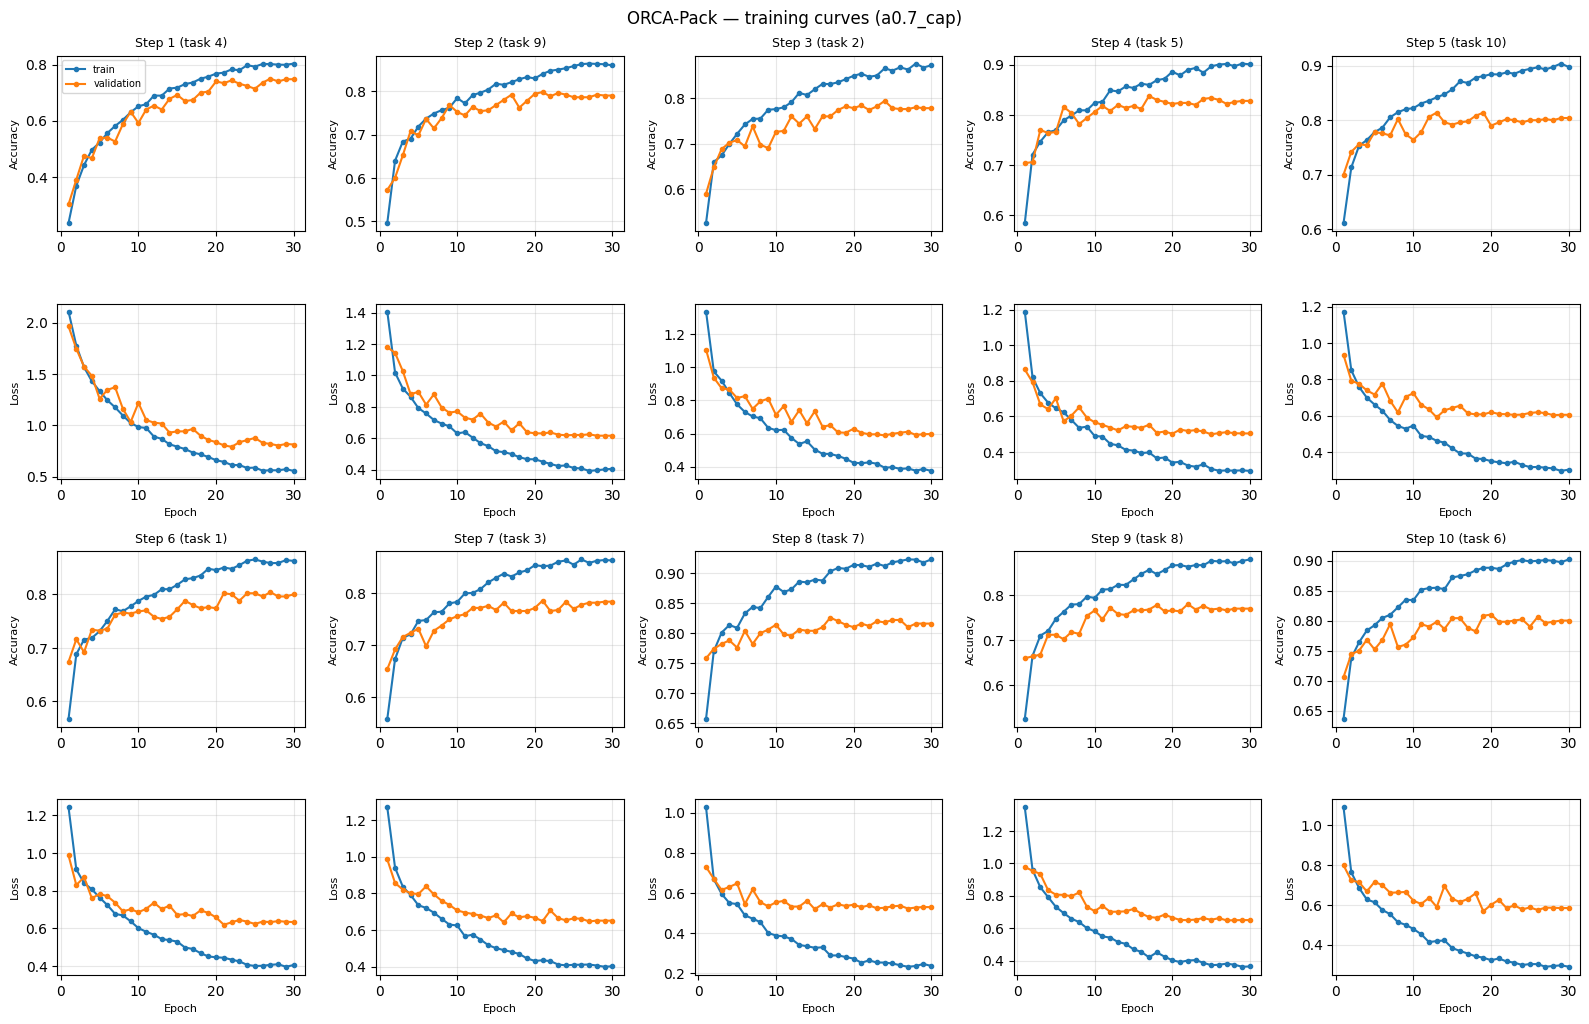

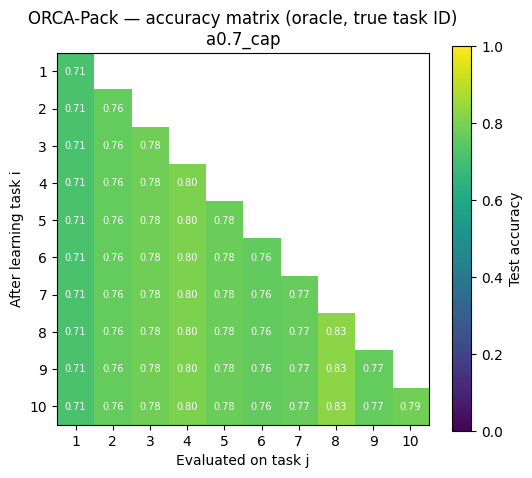

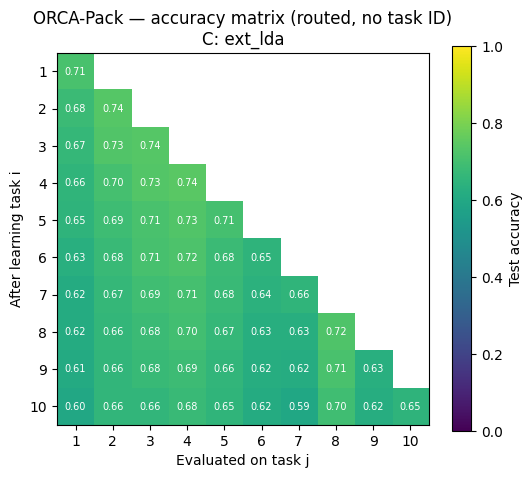

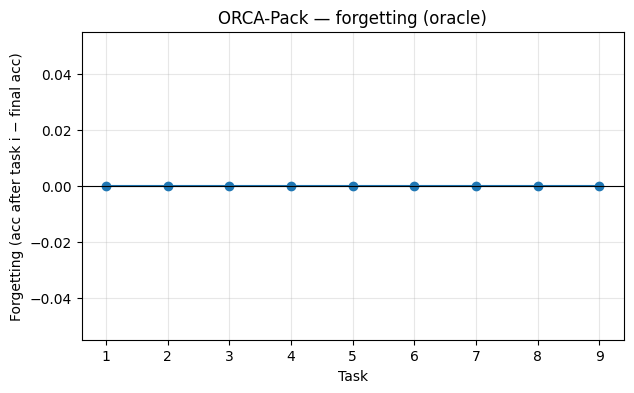

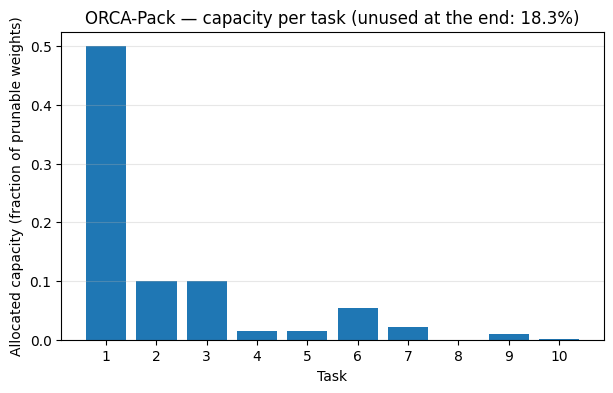

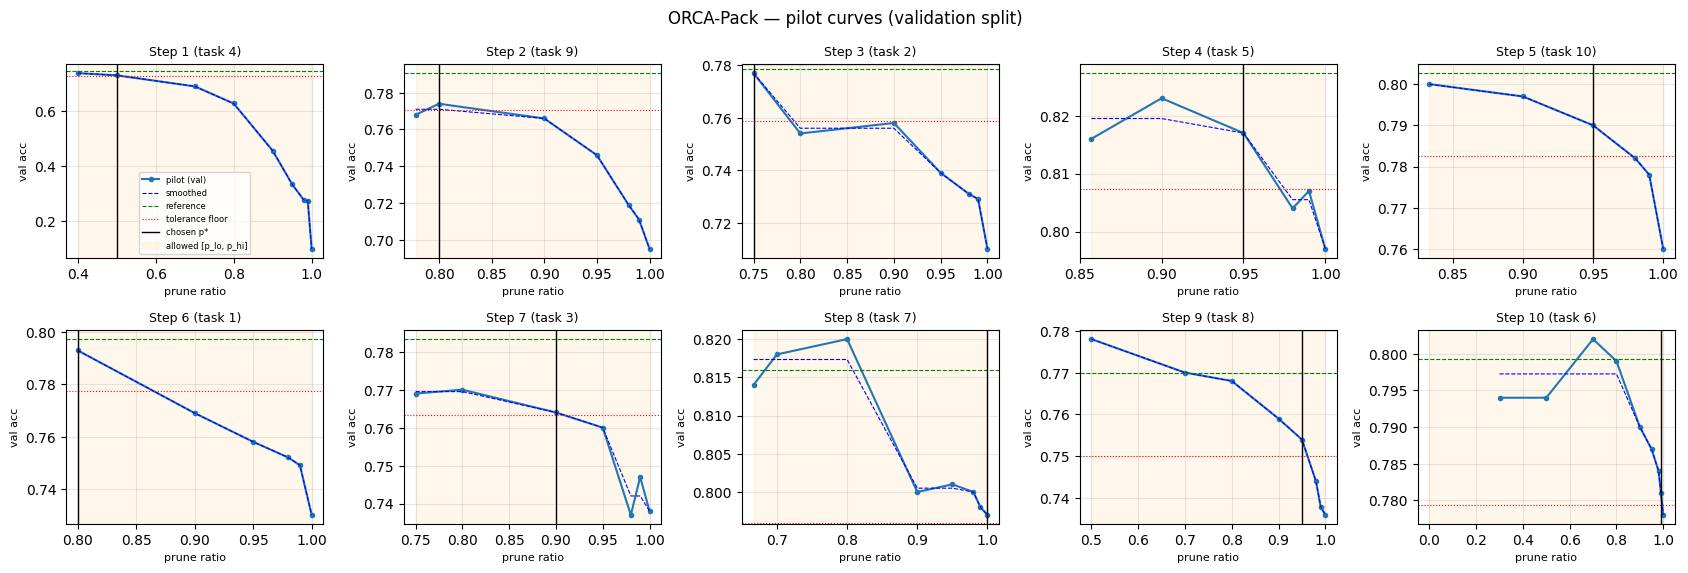

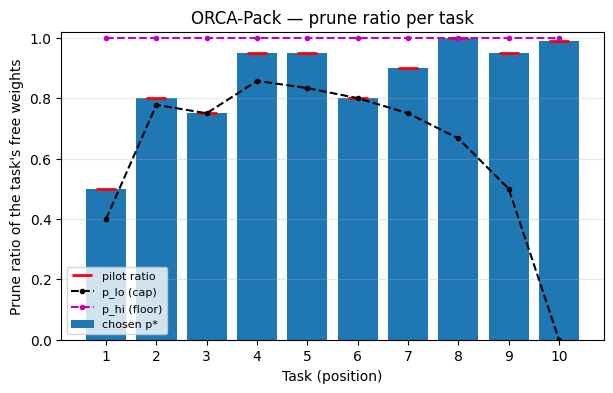

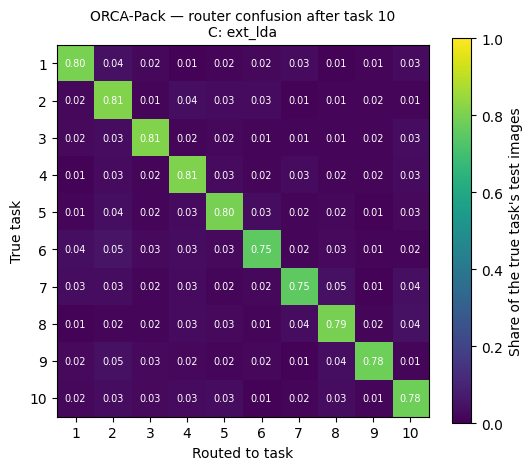

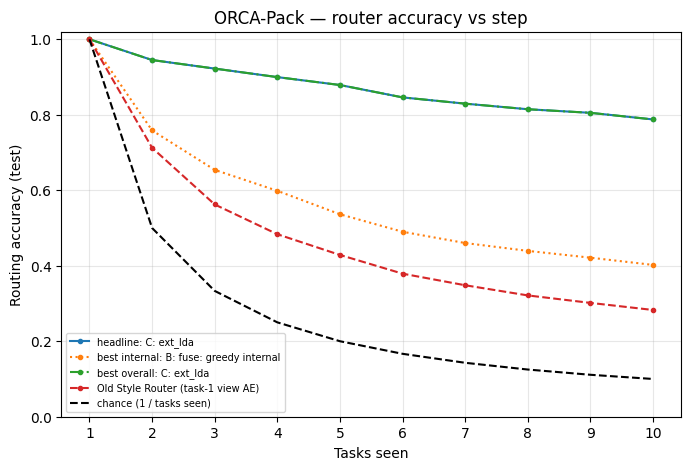

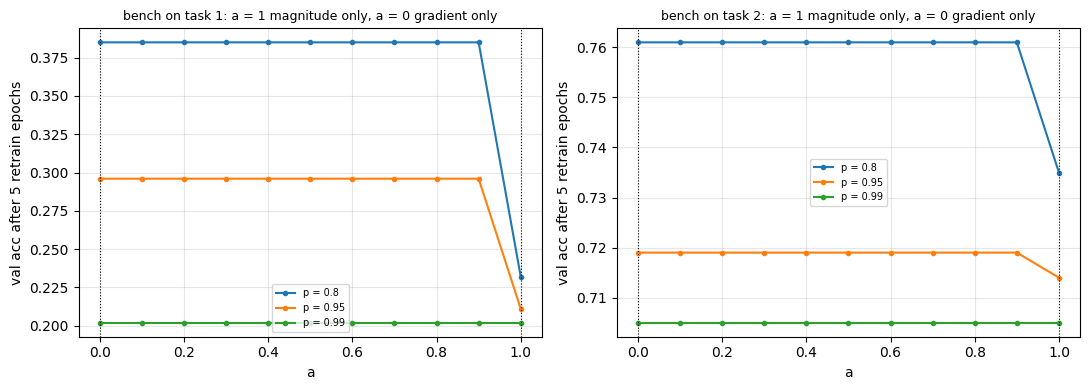

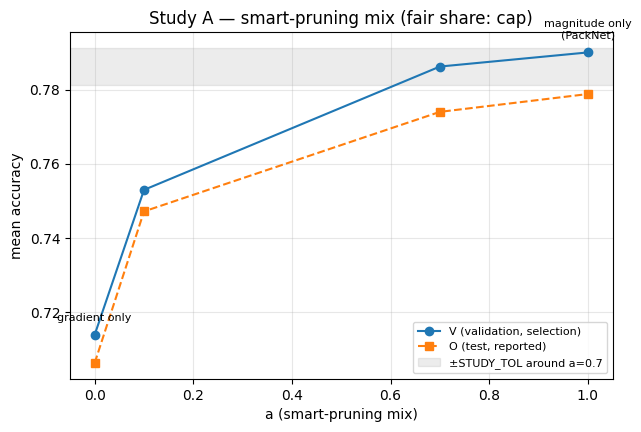

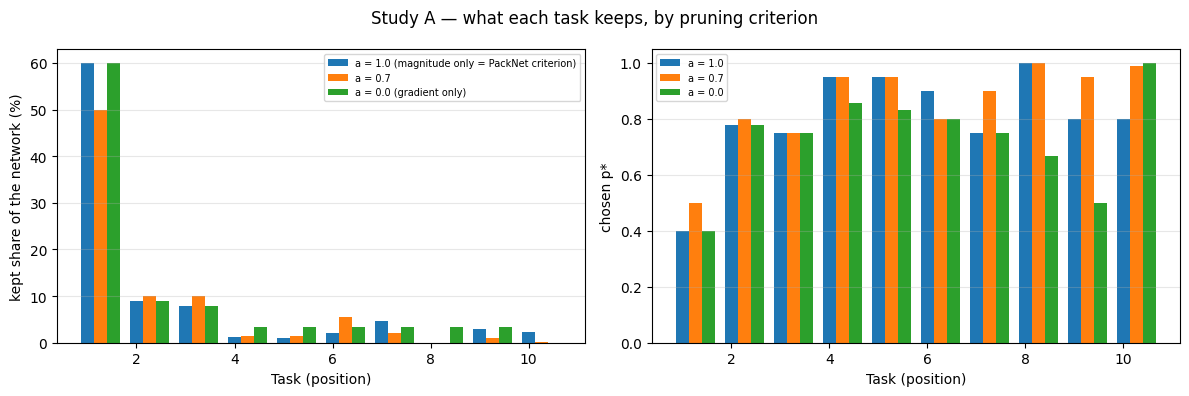

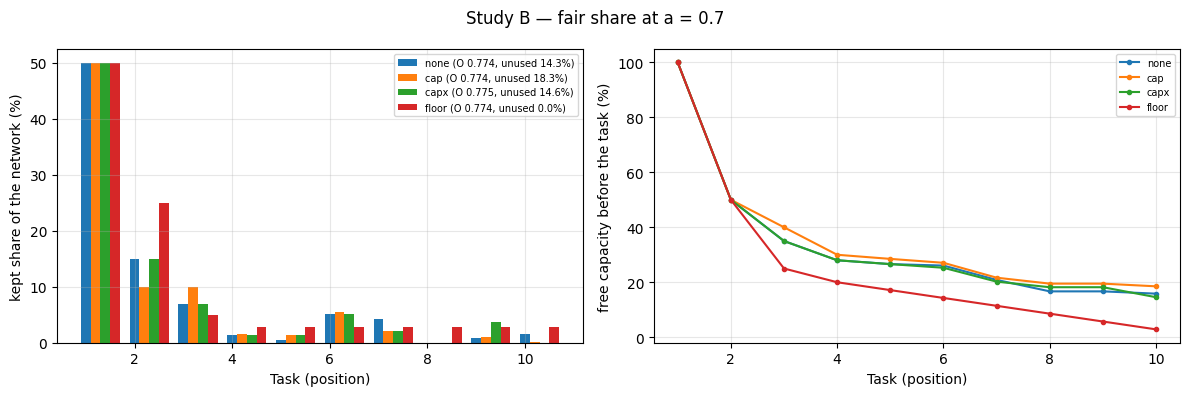

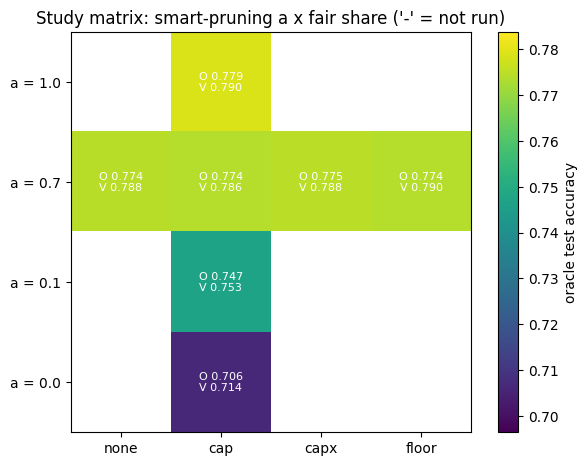

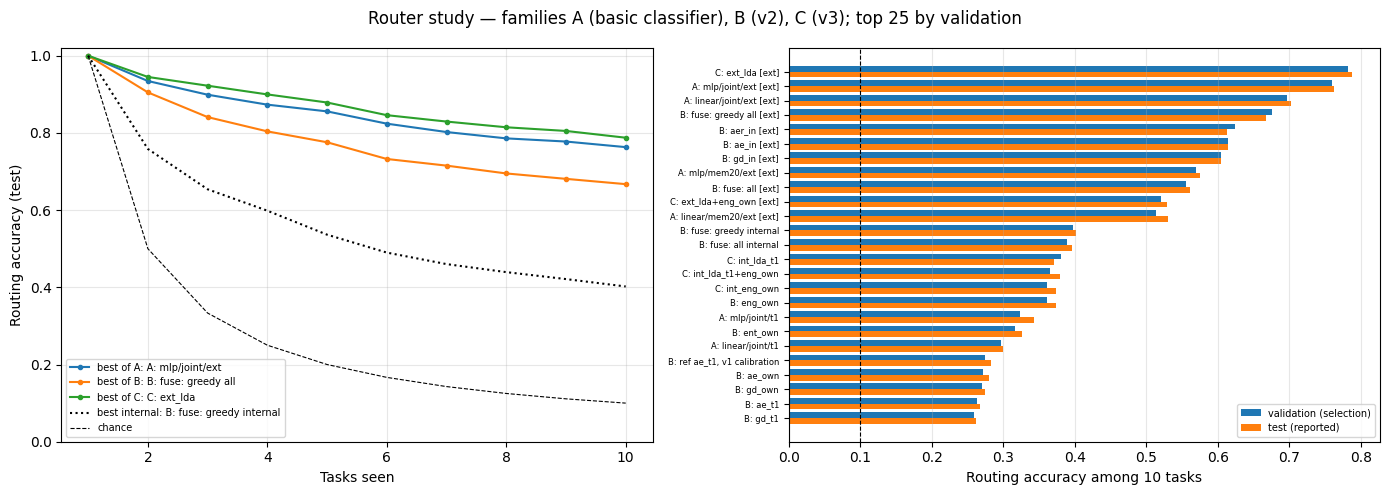

In [24]:
def _save(fig, name):
    fig.savefig(PLOT_DIR / f"orca_{name}.png", dpi=150, bbox_inches="tight")
    plt.show()

def plot_training_curves(histories, title):
    n_cols = 5
    n_blocks = math.ceil(len(histories) / n_cols)
    fig, axes = plt.subplots(2 * n_blocks, n_cols, figsize=(3.2 * n_cols, 2.6 * 2 * n_blocks), squeeze=False)
    for t, h in histories.items():
        r, c = divmod(t - 1, n_cols)
        for row, metric in ((2 * r, "accuracy"), (2 * r + 1, "loss")):
            ax = axes[row, c]
            ax.plot(h["epoch"], h[f"train_{metric}"], marker="o", ms=3, label="train")
            ax.plot(h["epoch"], h[f"validation_{metric}"], marker="o", ms=3, label="validation")
            ax.set_ylabel(metric.capitalize(), fontsize=8); ax.grid(alpha=0.3)
            if row == 2 * r:
                ax.set_title(f"Step {t} (task {ORDER[t - 1] + 1})", fontsize=9)
            else:
                ax.set_xlabel("Epoch", fontsize=8)
    axes[0, 0].legend(fontsize=7)
    for ax in axes.flat:
        if not ax.has_data():
            ax.axis("off")
    fig.suptitle(title)
    fig.tight_layout()
    _save(fig, "training_curves")

def plot_accuracy_matrix(mat, name, title):
    fig, ax = plt.subplots(figsize=(6, 5))
    im = ax.imshow(mat, vmin=0, vmax=1, cmap="viridis")
    ax.set_xlabel("Evaluated on task j"); ax.set_ylabel("After learning task i")
    ax.set_xticks(range(mat.shape[1])); ax.set_yticks(range(mat.shape[0]))
    ax.set_xticklabels(range(1, mat.shape[1] + 1)); ax.set_yticklabels(range(1, mat.shape[0] + 1))
    for i in range(mat.shape[0]):
        for j in range(mat.shape[1]):
            if not np.isnan(mat[i, j]):
                ax.text(j, i, f"{mat[i, j]:.2f}", ha="center", va="center", fontsize=7, color="w")
    fig.colorbar(im, ax=ax, label="Test accuracy"); ax.set_title(title)
    _save(fig, name)

def plot_forgetting(per_task):
    fig, ax = plt.subplots(figsize=(7, 4))
    ax.plot(range(1, len(per_task) + 1), per_task, marker="o", label="oracle")
    ax.axhline(0, color="k", lw=0.8)
    ax.set_xlabel("Task"); ax.set_ylabel("Forgetting (acc after task i − final acc)")
    ax.set_title("ORCA-Pack — forgetting (oracle)"); ax.grid(alpha=0.3)
    _save(fig, "forgetting")

def plot_capacity(alloc, free_fraction):
    fig, ax = plt.subplots(figsize=(7, 4))
    ax.bar(range(1, len(alloc) + 1), alloc)
    ax.set_xticks(range(1, len(alloc) + 1))
    ax.set_xlabel("Task"); ax.set_ylabel("Allocated capacity (fraction of prunable weights)")
    ax.set_title(f"ORCA-Pack — capacity per task (unused at the end: {free_fraction:.1%})"); ax.grid(alpha=0.3, axis="y")
    _save(fig, "capacity")

def plot_pilot_curves(info):
    n_cols = 5
    fig, axes = plt.subplots(math.ceil(N_TASKS / n_cols), n_cols, figsize=(3.4 * n_cols, 2.9 * math.ceil(N_TASKS / n_cols)), squeeze=False)
    for t in range(1, N_TASKS + 1):
        ax, d = axes[(t - 1) // n_cols, (t - 1) % n_cols], info[t]
        if d["curve"]:
            ps, accs = zip(*d["curve"])
            ax.plot(ps, accs, marker="o", ms=3, label="pilot (val)")
            if d["fitted"]:
                ax.plot(ps, d["fitted"], "b--", lw=0.8, label="smoothed")
        ax.axhline(d["ref"], color="g", ls="--", lw=0.8, label="reference")
        ax.axhline(d["ref"] - PILOT_TOL, color="r", ls=":", lw=0.8, label="tolerance floor")
        ax.axvline(d["p_star"], color="k", lw=1, label="chosen p*")
        ax.axvspan(d["p_lo"], d["p_hi"], color="orange", alpha=0.08, label="allowed [p_lo, p_hi]")
        if d["pilot_at_one"] is not None and d["p_hi"] < 1.0:
            ax.plot([1.0], [d["pilot_at_one"]], "kx", label="p=1.0 (diagnostic)")
        ax.set_title(f"Step {t} (task {ORDER[t - 1] + 1})" + (f" {d['bound']}-bound" if d["bound"] else ""), fontsize=9)
        ax.set_xlabel("prune ratio", fontsize=8); ax.set_ylabel("val acc", fontsize=8); ax.grid(alpha=0.3)
    axes[0, 0].legend(fontsize=6)
    fig.suptitle("ORCA-Pack — pilot curves (validation split)")
    fig.tight_layout()
    _save(fig, "pilot_curves")

def plot_prune_ratio(info):
    ts = range(1, N_TASKS + 1)
    fig, ax = plt.subplots(figsize=(7, 4))
    ax.bar(ts, [info[t]["p_star"] for t in ts], label="chosen p*")
    ax.plot(ts, [info[t]["p_pilot"] for t in ts], "r_", ms=14, mew=2, label="pilot ratio")
    ax.plot(ts, [info[t]["p_lo"] for t in ts], "k--", marker="o", ms=3, label="p_lo (cap)")
    ax.plot(ts, [info[t]["p_hi"] for t in ts], "m--", marker="o", ms=3, label="p_hi (floor)")
    ax.set_xticks(list(ts)); ax.set_ylim(0, 1.02)
    ax.set_xlabel("Task (position)"); ax.set_ylabel("Prune ratio of the task's free weights")
    ax.set_title("ORCA-Pack — prune ratio per task"); ax.grid(alpha=0.3, axis="y"); ax.legend(fontsize=8)
    _save(fig, "prune_ratio")

def plot_router_confusion(conf, name):
    M = conf / conf.sum(1, keepdims=True)
    fig, ax = plt.subplots(figsize=(6, 5))
    im = ax.imshow(M, vmin=0, vmax=1, cmap="viridis")
    ax.set_xlabel("Routed to task"); ax.set_ylabel("True task")
    ax.set_xticks(range(M.shape[1])); ax.set_yticks(range(M.shape[0]))
    ax.set_xticklabels(range(1, M.shape[1] + 1)); ax.set_yticklabels(range(1, M.shape[0] + 1))
    for i in range(M.shape[0]):
        for j in range(M.shape[1]):
            ax.text(j, i, f"{M[i, j]:.2f}", ha="center", va="center", fontsize=7, color="w")
    fig.colorbar(im, ax=ax, label="Share of the true task's test images")
    ax.set_title(f"ORCA-Pack — router confusion after task {M.shape[0]}\n{name}", fontsize=10)
    _save(fig, "router_confusion")

def plot_router_accuracy(curves):
    ts = list(range(1, N_TASKS + 1))
    fig, ax = plt.subplots(figsize=(8, 5))
    for label, acc_by_step, style in curves:
        ax.plot(ts, [acc_by_step[t] for t in ts], style, marker="o", ms=3, label=label)
    ax.plot(ts, [1 / t for t in ts], "k--", label="chance (1 / tasks seen)")
    ax.set_xticks(ts); ax.set_ylim(0, 1.02)
    ax.set_xlabel("Tasks seen"); ax.set_ylabel("Routing accuracy (test)")
    ax.set_title("ORCA-Pack — router accuracy vs step"); ax.grid(alpha=0.3); ax.legend(fontsize=7)
    _save(fig, "router_accuracy_vs_step")

# ---- study plots ----
def plot_study_a_bench():
    bench = STUDY_META["bench"]
    if not bench:
        return
    fig, axes = plt.subplots(1, len(bench), figsize=(5.5 * len(bench), 4), squeeze=False)
    for ax, (t, res) in zip(axes[0], sorted(bench.items())):
        a_vals = sorted(res)
        for p in BENCH_P:
            ax.plot(a_vals, [res[a][p] for a in a_vals], marker="o", ms=3, label=f"p = {p}")
        ax.axvline(1.0, color="k", ls=":", lw=0.8); ax.axvline(0.0, color="k", ls=":", lw=0.8)
        ax.set_title(f"bench on task {t}: a = 1 magnitude only, a = 0 gradient only", fontsize=9)
        ax.set_xlabel("a"); ax.set_ylabel(f"val acc after {BENCH_EPOCHS} retrain epochs"); ax.grid(alpha=0.3); ax.legend(fontsize=7)
    fig.tight_layout()
    _save(fig, "study_a_bench")

def plot_study_a():
    rows = sorted([r for r in STUDY.values() if r.get("candidate") and r["mode"] == LINEAGE_MODE and r["seed"] == SEED], key=lambda r: r["a"])
    if not rows:
        return
    fig, ax = plt.subplots(figsize=(7, 4.5))
    a_v = [r["a"] for r in rows]
    ax.plot(a_v, [r["V"] for r in rows], "o-", label="V (validation, selection)")
    ax.plot(a_v, [r["O"] for r in rows], "s--", label="O (test, reported)")
    base = STUDY[BASE]["V"]
    ax.axhspan(base - STUDY_TOL, base + STUDY_TOL, color="gray", alpha=0.15, label=f"±STUDY_TOL around a=0.7")
    for r in rows:
        if r["a"] in (0.0, 1.0):
            ax.annotate("gradient only" if r["a"] == 0 else "magnitude only\n(PackNet)", (r["a"], r["V"]), textcoords="offset points", xytext=(0, 10), ha="center", fontsize=8)
    ax.set_xlabel("a (smart-pruning mix)"); ax.set_ylabel("mean accuracy"); ax.set_title(f"Study A — smart-pruning mix (fair share: {LINEAGE_MODE})")
    ax.grid(alpha=0.3); ax.legend(fontsize=8)
    _save(fig, "study_a")

def plot_study_a_pertask():
    sel = [a for a in sorted({1.0, a_star_or_default(), 0.0}, reverse=True) if vname(a, LINEAGE_MODE) in STUDY]
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    w = 0.8 / max(len(sel), 1)
    for i, a in enumerate(sel):
        r = STUDY[vname(a, LINEAGE_MODE)]
        x = np.arange(1, N_TASKS + 1) + i * w
        axes[0].bar(x, [k * 100 for k in r["kept_share"]], width=w, label=f"a = {a:.1f}{a_label(a)}")
        axes[1].bar(x, r["p_star"], width=w, label=f"a = {a:.1f}")
    axes[0].set_ylabel("kept share of the network (%)"); axes[1].set_ylabel("chosen p*")
    for ax in axes:
        ax.set_xlabel("Task (position)"); ax.grid(alpha=0.3, axis="y"); ax.legend(fontsize=7)
    fig.suptitle("Study A — what each task keeps, by pruning criterion")
    fig.tight_layout()
    _save(fig, "study_a_pertask")

def plot_study_fs_capacity():
    a = a_star_or_default()
    names = [(m, vname(a, m)) for m in ("none", "cap", "capx", "floor") if vname(a, m) in STUDY]
    if not names:
        return
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    w = 0.8 / len(names)
    for i, (m, n) in enumerate(names):
        r = STUDY[n]
        axes[0].bar(np.arange(1, N_TASKS + 1) + i * w, [k * 100 for k in r["kept_share"]], width=w, label=f"{m} (O {r['O']:.3f}, unused {r['unused']:.1%})")
        axes[1].plot(range(1, N_TASKS + 1), [f * 100 for f in r["free_before"]], marker="o", ms=3, label=m)
    axes[0].set_ylabel("kept share of the network (%)"); axes[1].set_ylabel("free capacity before the task (%)")
    for ax in axes:
        ax.set_xlabel("Task (position)"); ax.grid(alpha=0.3); ax.legend(fontsize=7)
    fig.suptitle(f"Study B — fair share at a = {a}")
    fig.tight_layout()
    _save(fig, "study_fs_capacity")

def plot_study_matrix():
    rows = sorted({r["a"] for r in STUDY.values() if r.get("candidate") and r["seed"] == SEED}, reverse=True)
    modes = ["none", "cap", "capx", "floor"]
    M, V = np.full((len(rows), len(modes)), np.nan), np.full((len(rows), len(modes)), np.nan)
    for i, a in enumerate(rows):
        for j, m in enumerate(modes):
            hit = [r for r in STUDY.values() if r.get("candidate") and abs(r["a"] - a) < 1e-9 and r["mode"] == m and r["seed"] == SEED]
            if hit:
                M[i, j], V[i, j] = hit[0]["O"], hit[0]["V"]
    fig, ax = plt.subplots(figsize=(7, 0.8 * len(rows) + 2))
    im = ax.imshow(M, cmap="viridis", vmin=np.nanmin(M) - 0.01 if np.isfinite(M).any() else 0, vmax=np.nanmax(M) + 0.005 if np.isfinite(M).any() else 1)
    ax.set_xticks(range(len(modes))); ax.set_xticklabels(modes); ax.set_yticks(range(len(rows))); ax.set_yticklabels([f"a = {a:.1f}" for a in rows])
    for i in range(len(rows)):
        for j in range(len(modes)):
            ax.text(j, i, "-" if np.isnan(M[i, j]) else f"O {M[i, j]:.3f}\nV {V[i, j]:.3f}", ha="center", va="center", fontsize=8, color="w")
    fig.colorbar(im, ax=ax, label="oracle test accuracy")
    ax.set_title("Study matrix: smart-pruning a x fair share ('-' = not run)")
    _save(fig, "study_matrix")

def plot_router_families():
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    ts = list(range(1, N_TASKS + 1))
    for f, col in zip("ABC", ("tab:blue", "tab:orange", "tab:green")):
        n = fam_best[f]
        axes[0].plot(ts, [CANDS[n]["acc_by_step"][t] for t in ts], "-o", ms=3, color=col, label=f"best of {f}: {n}")
    axes[0].plot(ts, [CANDS[best_internal]["acc_by_step"][t] for t in ts], ":", color="k", label=f"best internal: {best_internal}")
    axes[0].plot(ts, [1 / t for t in ts], "k--", lw=0.8, label="chance")
    axes[0].set_xlabel("Tasks seen"); axes[0].set_ylabel("Routing accuracy (test)"); axes[0].set_ylim(0, 1.02); axes[0].grid(alpha=0.3); axes[0].legend(fontsize=7)
    order = sorted(CANDS, key=lambda n: -CANDS[n]["val"])[:25]
    y = np.arange(len(order))
    axes[1].barh(y - 0.2, [CANDS[n]["val"] for n in order], height=0.4, label="validation (selection)")
    axes[1].barh(y + 0.2, [CANDS[n]["test"] for n in order], height=0.4, label="test (reported)")
    axes[1].set_yticks(y); axes[1].set_yticklabels([n + (" [ext]" if CANDS[n]["external"] else "") for n in order], fontsize=6)
    axes[1].invert_yaxis(); axes[1].axvline(1 / N_TASKS, color="k", ls="--", lw=0.8)
    axes[1].set_xlabel(f"Routing accuracy among {N_TASKS} tasks"); axes[1].legend(fontsize=7); axes[1].grid(alpha=0.3, axis="x")
    fig.suptitle("Router study — families A (basic classifier), B (v2), C (v3); top 25 by validation")
    fig.tight_layout()
    _save(fig, "router_families")
    
plot_training_curves({t: HR["histories"][t]["train"] for t in HR["histories"]}, f"ORCA-Pack — training curves ({HEAD})")
plot_accuracy_matrix(R, "accuracy_matrix", f"ORCA-Pack — accuracy matrix (oracle, true task ID)\n{HEAD}")
plot_accuracy_matrix(R_routed, "accuracy_matrix_routed", f"ORCA-Pack — accuracy matrix (routed, no task ID)\n{HEAD_ROUTER}")
plot_forgetting(forget_oracle["per_task"])
plot_capacity(per_task_alloc, cap["free_fraction"])
plot_pilot_curves(orca.info)
plot_prune_ratio(orca.info)
plot_router_confusion(route_conf[N_TASKS], HEAD_ROUTER)
plot_router_accuracy([(f"headline: {HEAD_ROUTER}", route_acc_step, "-"), (f"best internal: {best_internal}", CANDS[best_internal]["acc_by_step"], ":"),
                      (f"best overall: {best_any}", CANDS[best_any]["acc_by_step"], "-."),
                      ("Old Style Router (task-1 view AE)", CANDS["B: ref ae_t1, v1 calibration"]["acc_by_step"], "--")])
plot_study_a_bench()
plot_study_a()
plot_study_a_pertask()
plot_study_fs_capacity()
plot_study_matrix()
plot_router_families()

In [25]:
print("DECISION LOG")
print(f"   noise: {STUDY_META['noise']}  -> STUDY_TOL = {STUDY_TOL:.4f}")
print(f"   Study A: a* = {STUDY_META['a_star']}{a_label(a_star_or_default())}")
print(f"   Study B: fair share = {STUDY_META['fs_star']} (lineage default {LINEAGE_MODE})")
print(f"   headline run = {HEAD} | headline router = {HEAD_ROUTER}")
study_table(sorted(cand_names, key=lambda n: -STUDY[n]["V"]), "ALL candidate runs (V = validation, O = test)")
if "M1" in STUDY:
    study_table(["M1"], "reference M1 (PackNet-R)")
study_matrix()

NB1_RESULTS = dict(
    headline=HEAD, a=HR["a"], mode=HR["mode"], V=HR["V"], O=HR["O"], unused=HR["unused"], forgetting=forget_oracle["average"],
    routed=final_routed, router=HEAD_ROUTER, routing_acc_T10=route_acc_step[N_TASKS], best_internal=best_internal,
    routed_internal=CANDS[best_internal]["final"], storage_mib=CANDS[HEAD_ROUTER]["total_mib"], storage_core_mib=core_total,
    per_task_oracle=np.diag(R).tolist(), per_task_routed=np.diag(R_routed).tolist(), stored_tol=STUDY_TOL,
    m1_O=STUDY["M1"]["O"] if "M1" in STUDY else None, run_minutes=HR["secs"] / 60,
    family_best={f: dict(name=fam_best[f], val=CANDS[fam_best[f]]["val"], test=CANDS[fam_best[f]]["test"], R_routed=CANDS[fam_best[f]]["final"]) for f in "ABC"},
    matrix={n: dict(a=r["a"], mode=r["mode"], V=r["V"], O=r["O"], unused=r["unused"]) for n, r in STUDY.items() if r.get("candidate")})
print("\nPaste this line into NB2 (config cell):")
print("NB1_RESULTS =", json.dumps(to_jsonable(NB1_RESULTS)))
print(f"\ntotal notebook time: {(time.time() - T_START) / 60:.1f} min")

DECISION LOG
   noise: {'V_seed': 0.7869999986648559, 'V_base': 0.7861999975204468, 'delta': 0.0008000011444091459, 'O_seed': 0.7696000397205353, 'O_base': 0.7740000307559967}  -> STUDY_TOL = 0.0050
   Study A: a* = 0.7
   Study B: fair share = cap (lineage default cap)
   headline run = a0.7_cap | headline router = C: ext_lda

ALL candidate runs (V = validation, O = test)
run                 a mode     V (val)  O (test)  forget  unused  bound  kept% min..max   min
a0.7_floor        0.7 floor     0.7902    0.7741  0.0000    0.0%      7   2.86..50.00%  22.4
a1.0_cap          1.0 cap       0.7900    0.7788  0.0000    9.1%      0   0.00..60.00%  26.6 (magnitude only = PackNet criterion)
a0.7_capx3        0.7 capx      0.7882    0.7746  0.0000   14.6%      0   0.00..50.00%  27.4
a0.7_none         0.7 none      0.7876    0.7744  0.0000   14.3%      0   0.00..50.00%  29.3
a0.7_cap          0.7 cap       0.7862    0.7740  0.0000   18.3%      0   0.00..50.00%  38.5
a0.1_cap          0.1 cap   